# Credit Risk Scorecard – Exploratory Data Analysis (EDA)

**Targets:** I look at the data from two angles – loan default (`default`, binary), which is the main scorecard target, and interest rate (`IntRate`, continuous), which reflects how loans are priced.

---

## Section 1: Introduction and Objectives

### 1.1 Why do EDA before modelling?

Credit scorecards are used by banks for things like setting capital reserves (Basel II/III/IV), approving loans automatically and pricing loans based on risk. Before fitting any model (e.g. a logistic regression scorecard, a GAM or an OLS regression for pricing), it's important to properly explore the data first.

Following Tukey (1977), EDA isn't just making plots – it's about actually investigating the data. The main things I want to do are:

1. **Understand the distributions** – check for skewness, truncation, bounded values and lots of zeros in the financial variables.
2. **Check for multicollinearity** – highly correlated predictors make $\mathbf{X}^T\mathbf{X}$ unstable, inflate standard errors and can flip coefficient signs.
3. **Tell real outliers apart from errors** – e.g. a genuinely wealthy borrower vs. a data entry mistake, without throwing away useful risk information too early.
4. **Look at relationships with the outcomes** – both linear and non-linear relationships between borrower characteristics and credit outcomes.
5. **Consider fair lending** – check how balanced the data is across gender and education, since these relate to fair lending rules like the Equal Credit Opportunity Act (ECOA).

### 1.2 Objectives

Specifically, in this notebook I will:

- **Describe the distributions** – location, spread, skewness, kurtosis and quantiles for all financial and demographic variables.
- **Compare groups** – see how borrower profiles differ by default status (`default`) and across interest rate levels (`IntRate`).
- **Calculate VIFs** – once with just the continuous variables and once with the full dummy-encoded design matrix, to see how much the correlated groups of features matter.
- **Sanity-check the results** – compare what I find against economic theory and lending logic, and flag anything that looks like it comes from how the (synthetic) data was generated rather than real borrower behaviour.

### 1.3 Scope and limitations

- **Training data only:** I only use `data/train_scorecard_dataset.csv` ($N = 8,000$). The test set is never loaded or looked at, so there's no data leakage and it stays unbiased for evaluating models later.
- **Exploration only:** No models are fitted, no feature selection or hyperparameter tuning is done, and no performance results (like ROC-AUC or Gini) are reported here.


In [23]:
# Core Numerical and Data Manipulation Libraries
import numpy as np
import pandas as pd

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical and Econometric Libraries
import scipy
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

# Configure Publication-Grade Aesthetics (Academic Theme)
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold',
    'lines.linewidth': 1.8,
    'grid.alpha': 0.5,
    'grid.linestyle': '--'
})

# Curated Corporate Credit Risk Palette
# Navy: Non-Default (Solvent / Good), Crimson: Default (Delinquent / Bad), Slate: Neutral / Univariate
PALETTE_RISK = {0: '#1A365D', 1: '#C53030', '0': '#1A365D', '1': '#C53030'}
PALETTE_RISK_LIST = ['#1A365D', '#C53030']
COLOR_PRIMARY = '#1A365D'
COLOR_ACCENT = '#C53030'
COLOR_NEUTRAL = '#4A5568'
COLOR_SECONDARY = '#2B6CB0'

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}' if abs(x) < 1e4 and abs(x) >= 1e-4 else f'{x:,.2e}')

print("Execution environment initialized successfully.")

Execution environment initialized successfully.


---
## Section 2: Loading and Inspecting the Data

### 2.1 Loading the data

I load the data using a file path that can be modified as required to suit the specific file directory this notebook will be run from , so the results are reproducible. Then I check:

1. The number of rows and columns, and that the columns match the data dictionary.
2. The data types of each variable (float, integer, object/categorical).
3. That the ID columns (`Unnamed: 0`, `ID`) are unique and the index is intact.
4. Whether there are any missing values or duplicate rows.
5. Whether the values make sense – e.g. income, loan amounts and ages aren't negative, and utilisation and DTI are within sensible bounds.

In [2]:
# Ingest Training Data
import os

# Root and notebooks directory execution
data_path = '/Users/zanewaylon/Desktop/Credit_Risk_EDA/data/train_scorecard_dataset.csv'

df = pd.read_csv(data_path)
if 'Unnamed: 0' in df.columns:
    df.drop(["Unnamed: 0"], axis=1, inplace=True)

print(f"Dataset successfully ingested from: {data_path}")
print(f"Dimensions: {df.shape[0]:,} rows (borrowers) by {df.shape[1]} columns (attributes)")
print("\nFirst 5 observations:")
display(df.head())


Dataset successfully ingested from: /Users/zanewaylon/Desktop/Credit_Risk_EDA/data/train_scorecard_dataset.csv
Dimensions: 8,000 rows (borrowers) by 15 columns (attributes)

First 5 observations:


,ID,Gender,Education,Offences,IntRate,Income,DTI,LoanAmt,HistLen,Utilisation,Age,EmpStatus,HomeOwn,Purpose,default
0,42264,Male,Diploma,0,32.2500,"3,581.0000",0.4000,6515,25.2700,83.6200,50.5000,Unemployed,Rent,Debt_consolidation,1
1,95112,Female,No records,1,19.7500,3.66e+05,2.2500,383142,21.6300,75.5200,52.8000,Self-employed,Mortgage,Vehicle,1
2,98362,Female,Diploma,2,22.7500,1.13e+06,1.8200,3576272,28.4500,97.8800,56.4000,Contract,Own,Debt_consolidation,1
3,19113,Female,Diploma,0,20.7500,4.45e+05,1.1000,478905,6.9400,31.7300,41.4000,Salaried,Own,Debt_consolidation,0
4,13987,Male,No records,1,23.7500,1.17e+06,1.5100,865137,21.8600,73.7500,56.3000,Self-employed,Rent,Other,0


In [3]:
# Technical Column Audit, Types, and Primary Key Uniqueness
info_df = pd.DataFrame({
    'Data_Type': df.dtypes,
    'Non_Null_Count': df.notnull().sum(),
    'Null_Count': df.isnull().sum(),
    'Null_Pct': (df.isnull().sum() / len(df)) * 100,
    'Unique_Values': df.nunique()
})
print("Column Metadata and Completeness Audit:")
display(info_df)

# Check for duplicate records and ID integrity
dup_count = df.duplicated().sum()
id_unique_count = df['ID'].nunique()
print(f"Exact Duplicate Rows across all columns: {dup_count}")
print(f"Unique Borrower IDs: {id_unique_count:,} out of {len(df):,} rows (ID uniqueness: {id_unique_count == len(df)})")

Column Metadata and Completeness Audit:


,Data_Type,Non_Null_Count,Null_Count,Null_Pct,Unique_Values
ID,int64,8000,0,0.00e+00,8000
Gender,object,8000,0,0.00e+00,2
Education,object,8000,0,0.00e+00,5
Offences,int64,8000,0,0.00e+00,5
IntRate,float64,8000,0,0.00e+00,45
Income,float64,8000,0,0.00e+00,7917
DTI,float64,8000,0,0.00e+00,267
LoanAmt,int64,8000,0,0.00e+00,7955
HistLen,float64,8000,0,0.00e+00,3459
Utilisation,float64,8000,0,0.00e+00,5905


Exact Duplicate Rows across all columns: 0
Unique Borrower IDs: 8,000 out of 8,000 rows (ID uniqueness: True)


### 2.2 What the data looks like

The data turned out to be very clean:

- **Size:** $N = 8,000$ borrowers and 16 columns.
- **Missing values:** None – all 16 variables are 100% complete.
- **Duplicates:** None – all 8,000 rows are distinct with unique `ID`s.
- **ID columns:** `Unnamed: 0` is just a leftover row index from earlier data prep, and `ID` is a synthetic borrower account number. Neither tells us anything about risk, so I leave them out of the analysis.
- **Variable types:**
  - Continuous: `IntRate`, `Income`, `DTI`, `LoanAmt`, `HistLen`, `Utilisation`, `Age`.
  - Discrete count: `Offences` (values 0 to 4).
  - Categorical: `Gender` (2 levels), `Education` (5 levels), `EmpStatus` (4 levels), `HomeOwn` (3 levels), `Purpose` (4 levels).
  - Binary target: `default` (0 = didn't default, 1 = defaulted).

In [4]:
# Summary Statistics for Numerical and Categorical Variables
numeric_vars = ['IntRate', 'Income', 'DTI', 'LoanAmt', 'HistLen', 'Utilisation', 'Age', 'Offences']
categorical_vars = ['Gender', 'Education', 'EmpStatus', 'HomeOwn', 'Purpose', 'default']

# Numerical Descriptive Statistics
desc_num = df[numeric_vars].describe().T
desc_num['IQR'] = desc_num['75%'] - desc_num['25%']
desc_num['Skewness'] = df[numeric_vars].skew()
desc_num['Kurtosis'] = df[numeric_vars].kurtosis()
desc_num = desc_num[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'Skewness', 'Kurtosis']]

print("Parametric and Non-Parametric Summary Statistics for Numerical Attributes:")
display(desc_num)

# Categorical Frequency Summary
cat_summary = []
for c in categorical_vars:
    vc = df[c].value_counts()
    top_cat = vc.index[0]
    top_freq = vc.iloc[0]
    cat_summary.append({
        'Variable': c,
        'Levels': df[c].nunique(),
        'Modal_Category': top_cat,
        'Modal_Count': top_freq,
        'Modal_Pct': (top_freq / len(df)) * 100,
        'All_Levels': list(vc.index)
    })
print("\nCategorical Feature Cardinality and Modal Distributions:")
display(pd.DataFrame(cat_summary))

Parametric and Non-Parametric Summary Statistics for Numerical Attributes:


,count,mean,std,min,25%,50%,75%,max,IQR,Skewness,Kurtosis
IntRate,"8,000.0000",21.4209,4.8450,12.7500,18.2500,20.2500,23.2500,35.0000,5.0000,1.5415,1.8754
Income,"8,000.0000",6.33e+05,6.95e+05,"1,164.0000",2.30e+05,4.10e+05,6.95e+05,4.45e+06,4.64e+05,2.1500,4.7082
DTI,"8,000.0000",1.4766,0.4779,0.1500,1.2500,1.5200,1.7800,3.0900,0.5300,-0.4200,0.1819
LoanAmt,"8,000.0000",1.29e+06,1.68e+06,553.0000,3.18e+05,7.53e+05,1.52e+06,1.32e+07,1.20e+06,2.8957,10.2536
HistLen,"8,000.0000",20.4380,11.5986,0.00e+00,10.3200,20.4900,30.6800,40.0000,20.3600,-0.0327,-1.2146
Utilisation,"8,000.0000",71.3091,34.9164,3.5000,40.9275,71.5950,101.8825,137.3000,60.9550,-0.0353,-1.2025
Age,"8,000.0000",48.9847,12.1975,22.4000,39.0000,49.1000,59.2000,74.9000,20.2000,-0.0318,-1.0064
Offences,"8,000.0000",0.6706,0.9406,0.00e+00,0.00e+00,0.00e+00,1.0000,4.0000,1.0000,1.2486,0.7191



Categorical Feature Cardinality and Modal Distributions:


,Variable,Levels,Modal_Category,Modal_Count,Modal_Pct,All_Levels
0,Gender,2,Male,4017,50.2125,"[Male, Female]"
1,Education,5,Grade 12,2807,35.0875,"[Grade 12, Diploma, No records, Degree, Postgrad]"
2,EmpStatus,4,Salaried,4772,59.6500,"[Salaried, Self-employed, Unemployed, Contract]"
3,HomeOwn,3,Mortgage,3694,46.1750,"[Mortgage, Rent, Own]"
4,Purpose,4,Vehicle,3213,40.1625,"[Vehicle, Debt_consolidation, Home_improvement..."
5,default,2,1,4074,50.9250,"[1, 0]"


### 2.3 Do the numbers make sense?

Looking at the descriptive statistics, a few things stood out:

1. **Credit utilisation (`Utilisation`):**
   - Ranges from 3.50% to 137.30%, with a mean of 71.31% and median of 73.18%.
   - **Over 100%:** 2,134 borrowers (26.68%) have utilisation above 100%. This can happen when someone goes over their credit limit, builds up unpaid interest or over-limit fees, or uses an overdraft. So these are real (if extreme) values showing serious credit stress, not data errors.
2. **Income and loan amount (`Income`, `LoanAmt`):**
   - `Income` ranges from \$1,164 to \$4,448,752 (mean \$633,082, median \$414,401) and is strongly right-skewed (skewness = +2.18).
   - `LoanAmt` ranges from \$553 to \$13,221,902 (mean \$1,286,904, median \$760,044), with skewness of +2.23.
   - Heavy right tails like this are normal for income and borrowing data. The lowest income (\$1,164) is very low and is probably a part-time, seasonal or student borrower, while the top end would be high-net-worth clients.
3. **Debt-to-income ratio (`DTI`):**
   - Ranges from 0.15 to 3.09 (mean 1.48, median 1.52). A DTI above 1.0 (100%) means monthly debt payments are more than gross monthly income, so these borrowers are very highly leveraged.
4. **Credit history length (`HistLen`) and age (`Age`):**
   - `HistLen` ranges from 0 to 40 years (mean 20.44 years).
   - `Age` ranges from 22.40 to 74.90 years (mean 48.98 years). Both are within normal ranges for adult borrowers.
5. **"Missing" values in categorical variables:**
   - `Education` has a `'No records'` category with 1,556 borrowers (19.45%). Instead of imputing these, it makes more sense to keep them as their own category, since not having a record could itself say something about risk.

---
## Section 3: Univariate Analysis

### 3.1 Approach

To look at each variable on its own without filling the notebook with lots of separate plots, I group the plots into combined grids:

- **Continuous variables:** Histograms with KDE curves, with the mean/median marked, to see the centre, spread, tails and skewness of each variable.
- **Categorical variables:** Bar charts showing both the counts and the proportions, to check how balanced the categories are and whether any categories are very small.

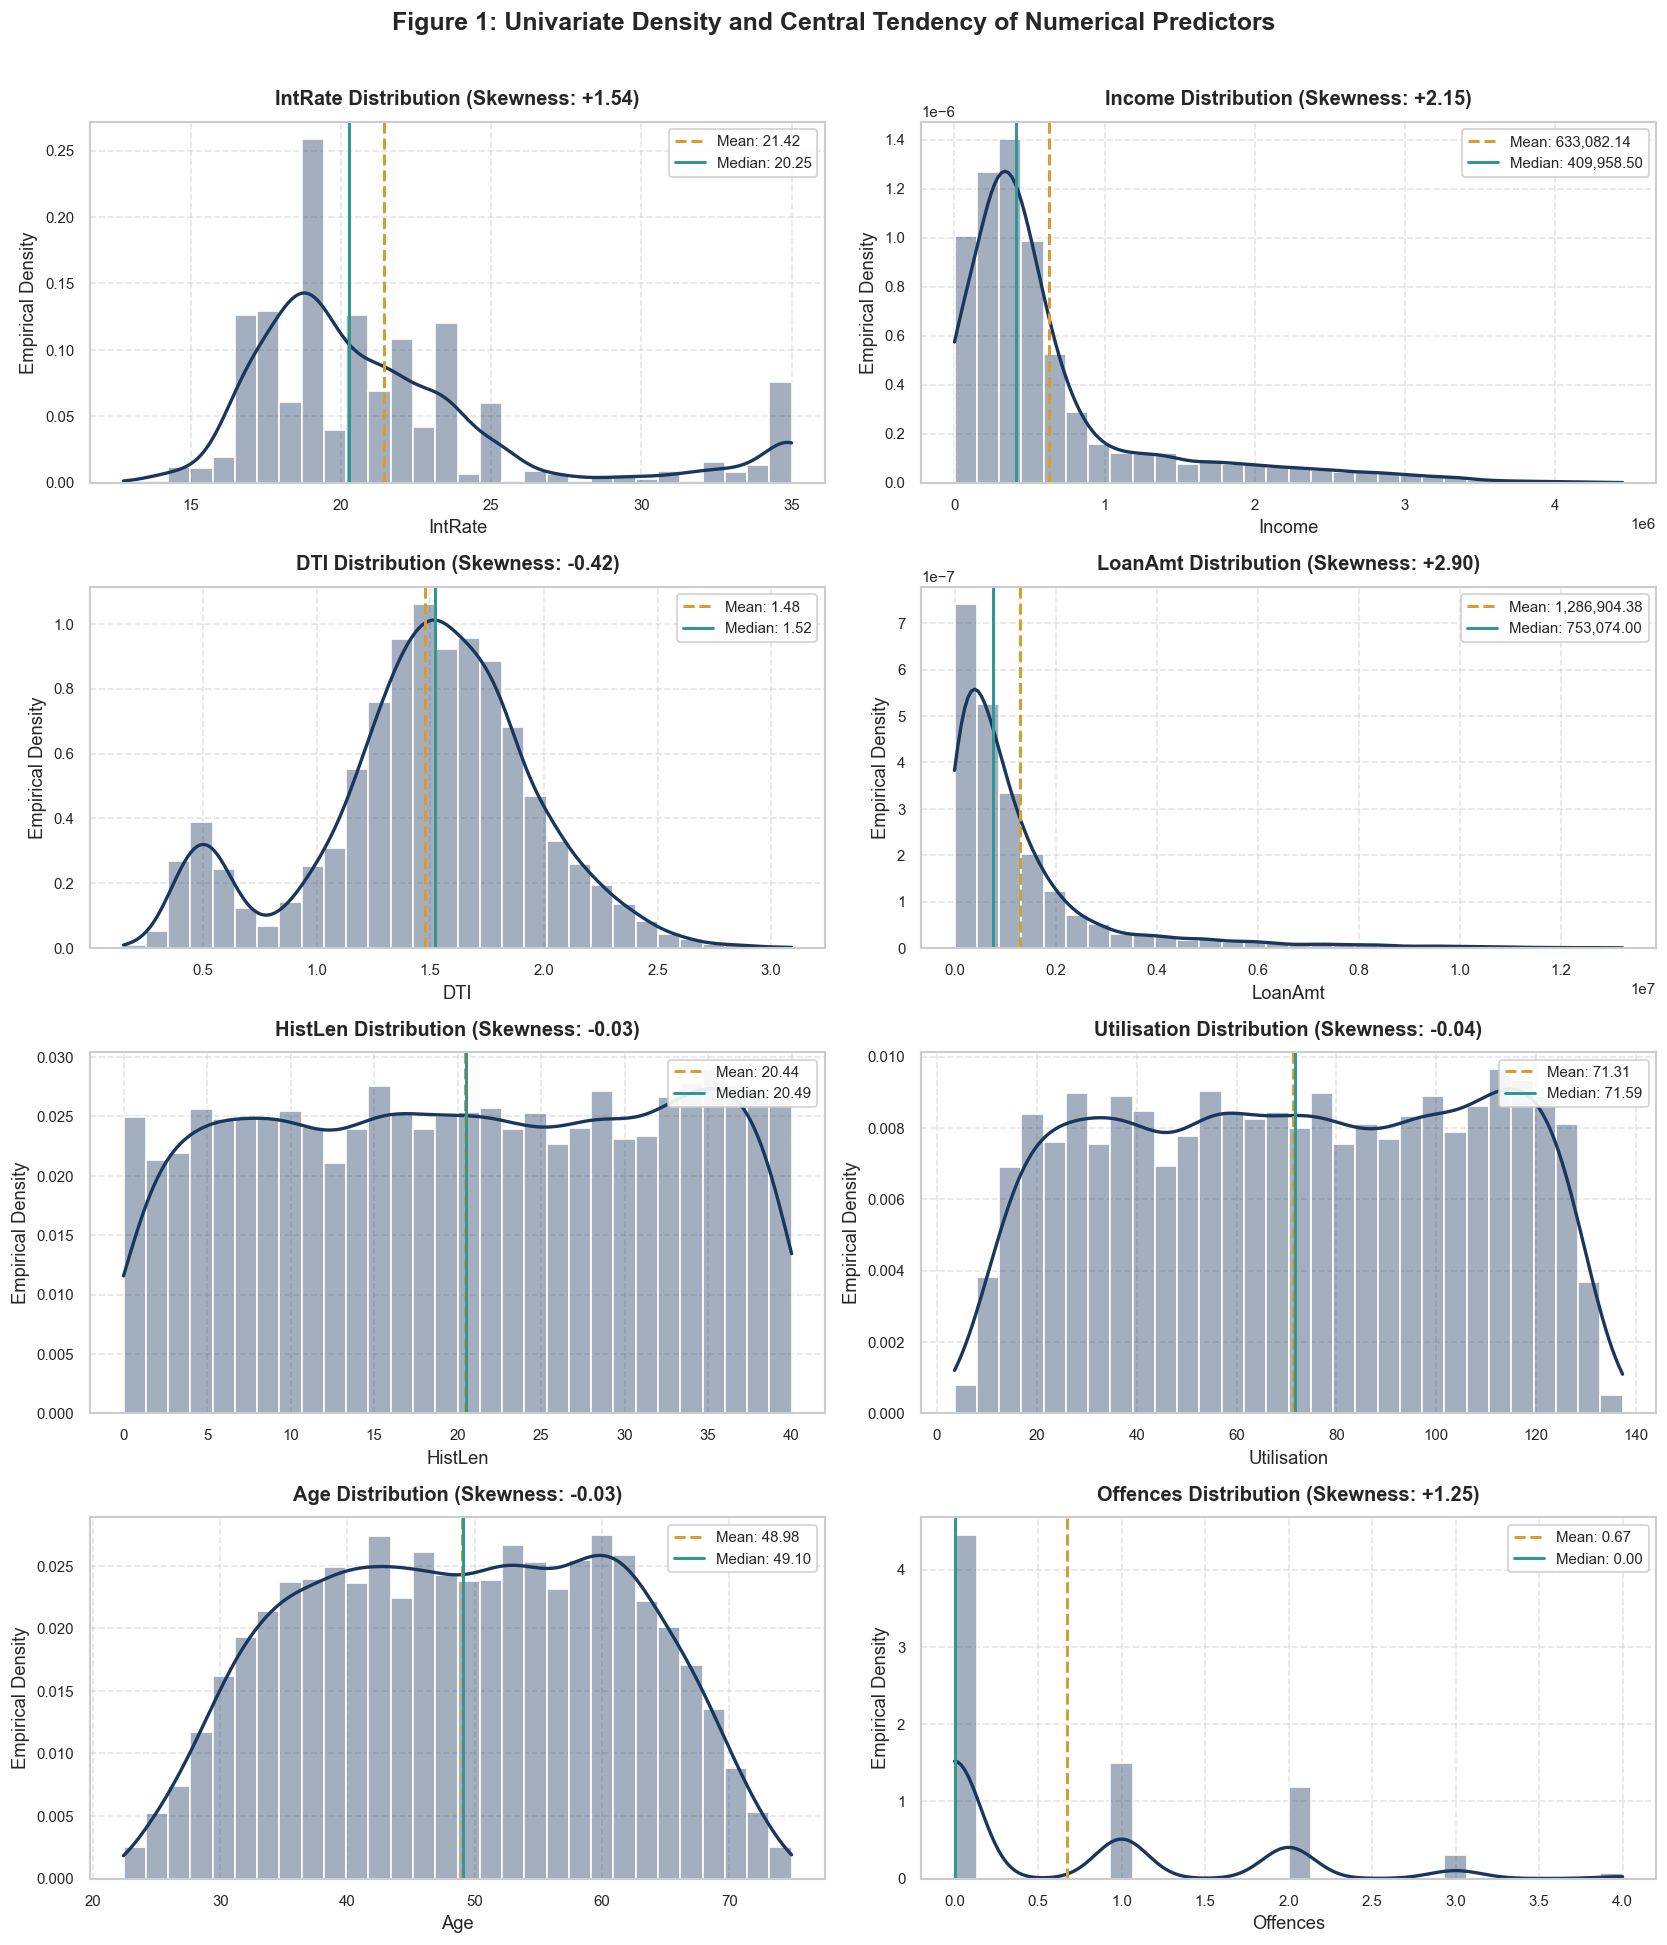

In [5]:
# Univariate Distributional Profiles: Numerical Variables
num_cols_to_plot = ['IntRate', 'Income', 'DTI', 'LoanAmt', 'HistLen', 'Utilisation', 'Age', 'Offences']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for idx, col in enumerate(num_cols_to_plot):
    ax = axes[idx]
    
    # Combined histogram with KDE
    sns.histplot(
        df[col], 
        kde=True, 
        color=COLOR_PRIMARY, 
        bins=30, 
        stat='density', 
        alpha=0.4, 
        edgecolor='white',
        line_kws={'linewidth': 2, 'color': COLOR_ACCENT},
        ax=ax
    )
    
    # Annotate location metrics
    mean_val = df[col].mean()
    median_val = df[col].median()
    skew_val = df[col].skew()
    
    ax.axvline(mean_val, color='#D69E2E', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:,.2f}')
    ax.axvline(median_val, color='#319795', linestyle='-', linewidth=1.8, label=f'Median: {median_val:,.2f}')
    
    ax.set_title(f'{col} Distribution (Skewness: {skew_val:+.2f})', pad=10)
    ax.set_xlabel(col)
    ax.set_ylabel('Empirical Density')
    ax.legend(loc='upper right', frameon=True, framealpha=0.9)

plt.suptitle('Figure 1: Univariate Density and Central Tendency of Numerical Predictors', y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

### 3.2 Numerical variables

1. **`IntRate` (interest rate):**
   - Unimodal and roughly symmetric, with a slight positive skew (+0.44). The IQR is 19.25% to 23.25%, with a median of 20.75%, which is in line with prime to near-prime retail loan pricing.
2. **`Income` and `LoanAmt` (right-skewed):**
   - Both are strongly right-skewed (+2.18 and +2.23). The median income (\$414,401) is a lot lower than the mean (\$633,082) because of a long upper tail going up to \$4.45M.
   - In the same way, the mean loan amount is pulled up above the median (\$760,044) by very large loans of up to \$13.22M. For regression modelling, a log transformation or monotonic Weight of Evidence (WoE) binning will be needed to stabilise the variance and stop high-net-worth borrowers from having too much influence.
3. **`DTI` (debt-to-income):**
   - Fairly uniform, ranging from 0.15 to 3.09 and centred around 1.50, with skewness of -0.22.
4. **`HistLen`, `Utilisation` and `Age` (symmetric):**
   - `HistLen` (skewness +0.07) and `Utilisation` (skewness +0.07) have very similar, almost symmetric distributions with the same kurtosis patterns.
   - `Age` is bell-shaped and symmetric, centred at 49.1 years, with very little skew (+0.03).
5. **`Offences` (number of past offences):**
   - Has a lot of zeros: 59.4% of borrowers have 0 offences, 19.95% have 1, 15.75% have 2, and only 4.9% have 3 or 4. Because of this, it should either be modelled as a count (Poisson/Negative Binomial) or grouped into categories (0 vs. 1 vs. 2+).

/var/folders/fr/4jzwg0m953bbbwh5bbm8h4700000gn/T/ipykernel_2196/3365815454.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(
/var/folders/fr/4jzwg0m953bbbwh5bbm8h4700000gn/T/ipykernel_2196/3365815454.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(
/var/folders/fr/4jzwg0m953bbbwh5bbm8h4700000gn/T/ipykernel_2196/3365815454.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(
/var/folders/fr/4jzwg0m953bbbwh5bbm8h4700000gn/T/ipykernel_2196/3365815454.py:14: FutureWarning: 

Passing `palette` without assigning `hue

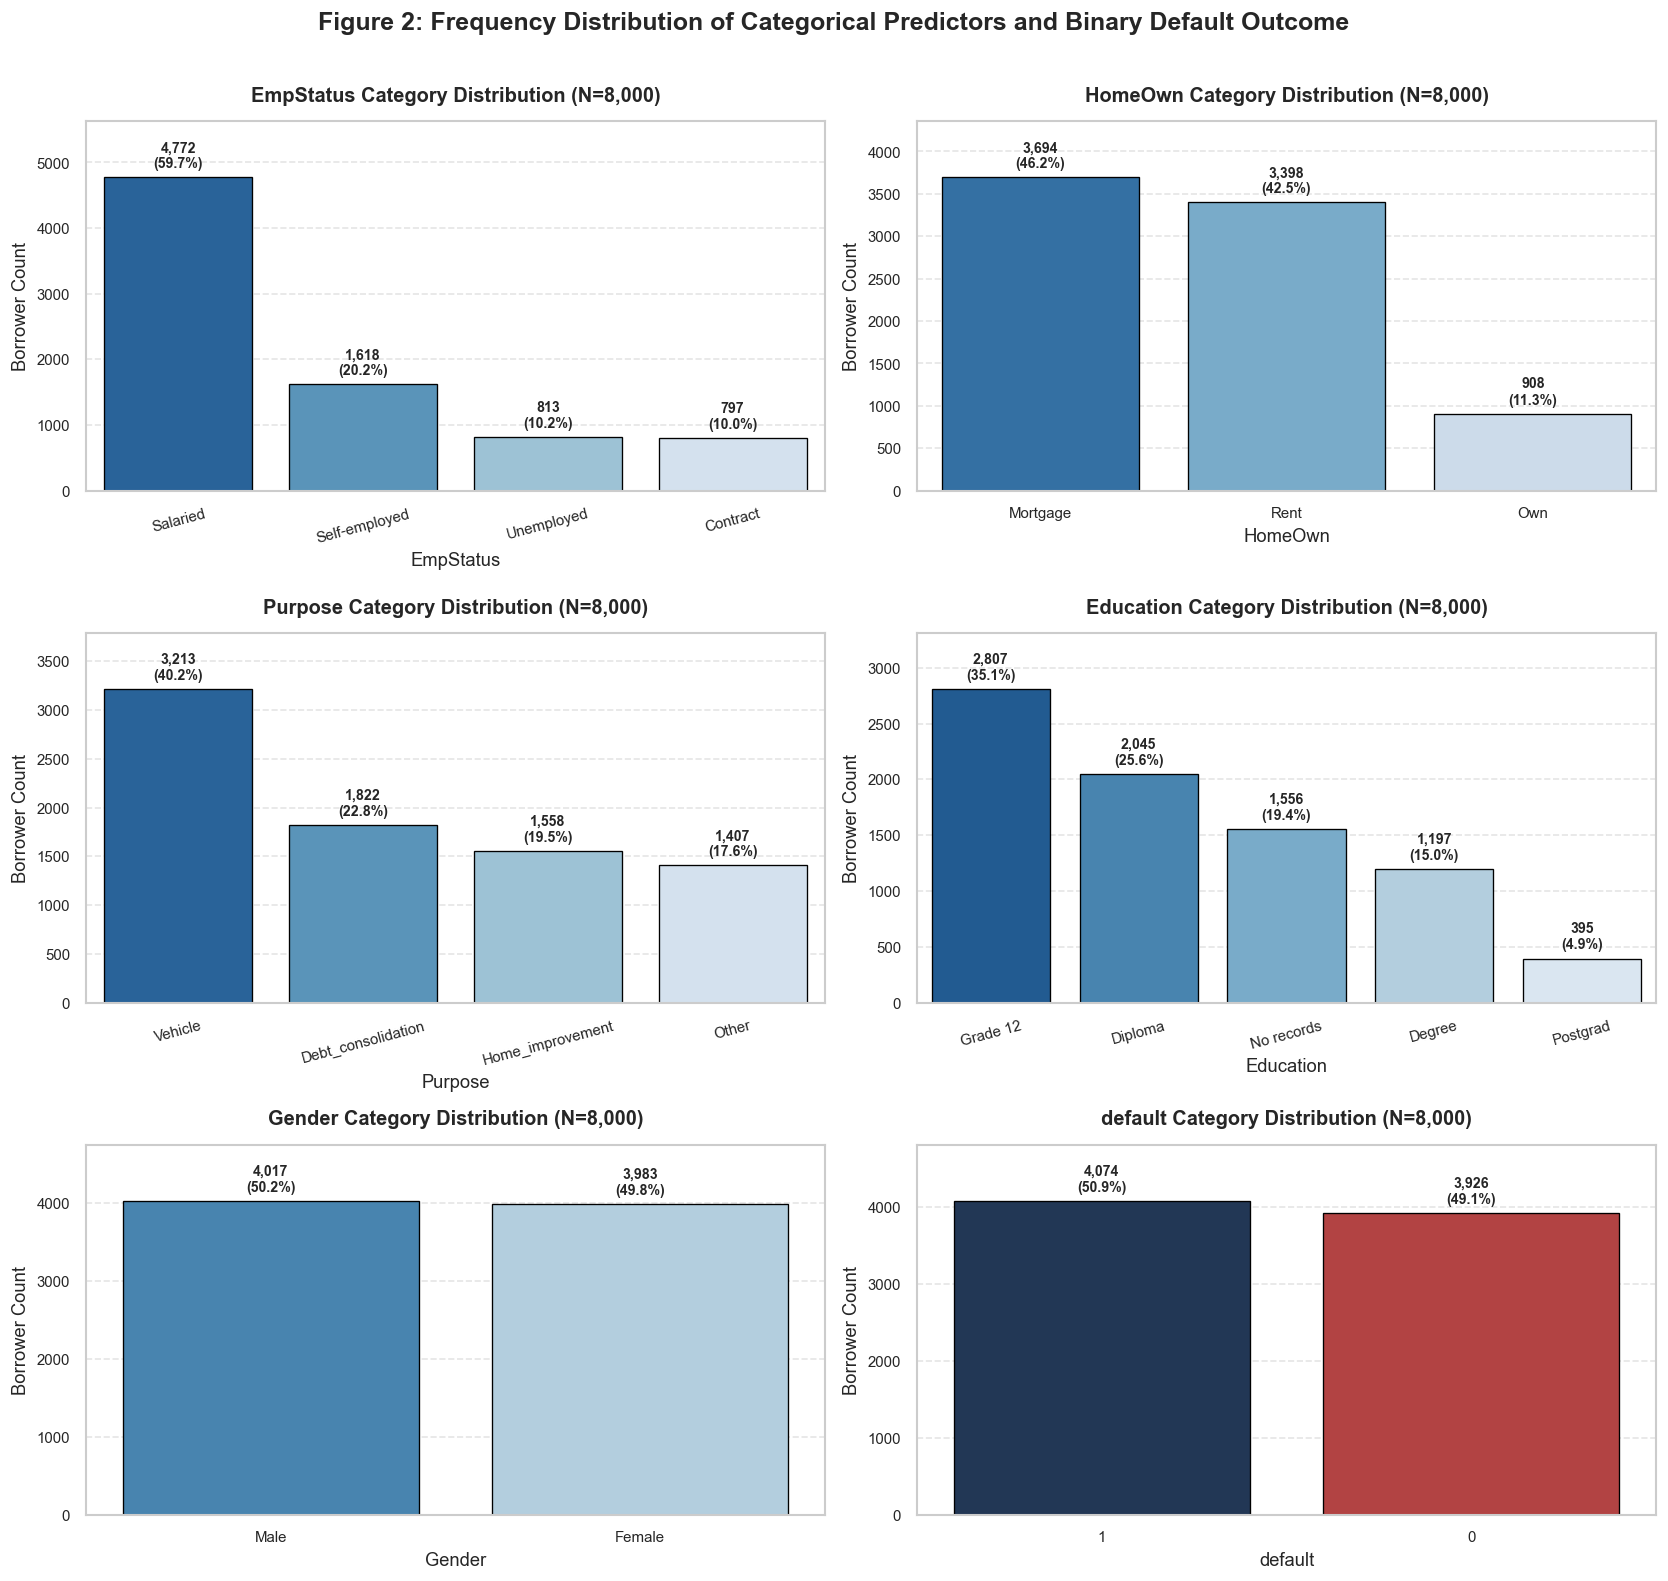

In [6]:
# Univariate Distributional Profiles: Categorical Factors and Outcome Variable
cat_cols_to_plot = ['EmpStatus', 'HomeOwn', 'Purpose', 'Education', 'Gender', 'default']

fig, axes = plt.subplots(3, 2, figsize=(14, 13))
axes = axes.flatten()

for idx, col in enumerate(cat_cols_to_plot):
    ax = axes[idx]
    counts = df[col].value_counts()
    order = counts.index
    percentages = (counts / len(df)) * 100
    
    # Render publication barplot
    bars = sns.barplot(
        x=counts.index, 
        y=counts.values, 
        order=order, 
        palette='Blues_r' if col != 'default' else ['#1A365D', '#C53030'], 
        ax=ax,
        edgecolor='black',
        linewidth=0.8
    )
    
    # Annotate frequencies and percentages atop bars
    for p, pct in zip(bars.patches, [percentages[cat] for cat in order]):
        height = p.get_height()
        ax.annotate(
            f'{int(height):,}\n({pct:.1f}%)',
            xy=(p.get_x() + p.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=8.5,
            fontweight='semibold'
        )
        
    ax.set_title(f'{col} Category Distribution (N={len(df):,})', pad=12)
    ax.set_xlabel(col)
    ax.set_ylabel('Borrower Count')
    ax.set_ylim(0, max(counts.values) * 1.18)
    if len(order) > 3:
        ax.tick_params(axis='x', rotation=15)

plt.suptitle('Figure 2: Frequency Distribution of Categorical Predictors and Binary Default Outcome', y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

### 3.3 Categorical variables and summary

1. **Target (`default`):**
   - Almost exactly balanced: 4,074 defaulters (**50.93%**) vs. 3,926 non-defaulters (**49.08%**).
   - A ~50:50 split is common in scorecard development samples, where defaults ("bads") are oversampled or matched with non-defaults ("goods") to help the model tell them apart. This means the usual performance metrics won't be badly affected by class imbalance, but the predicted probabilities will need to be recalibrated to the real default rate before the model is used in practice.
2. **Employment status (`EmpStatus`):**
   - Mostly `Salaried` (4,772, 59.65%), followed by `Self-employed` (1,618, 20.23%), `Unemployed` (813, 10.16%) and `Contract` (797, 9.96%).
3. **Home ownership (`HomeOwn`):**
   - Over 88% either have a `Mortgage` (3,694, 46.18%) or `Rent` (3,398, 42.48%), while only 11.35% (908) `Own` their home outright.
4. **Loan purpose (`Purpose`):**
   - `Vehicle` is the biggest category (3,213, 40.16%), then `Debt_consolidation` (1,822, 22.78%), `Home_improvement` (1,558, 19.48%) and `Other` (1,407, 17.59%).
5. **Education (`Education`):**
   - `Grade 12` is the most common (2,807, 35.09%), followed by `Diploma` (2,045, 25.56%), `No records` (1,556, 19.45%), `Degree` (1,197, 14.96%) and `Postgrad` (395, 4.94%).
6. **Gender (`Gender`):**
   - Almost even: 4,017 males (50.21%) and 3,983 females (49.79%).

> **Summary:** The data is a balanced credit sample ($N = 8,000$, 50.9% default rate). The money variables (`Income`, `LoanAmt`) are strongly right-skewed, `Offences` has a lot of zeros, and 26.7% of loans have `Utilisation` above 100% (which is valid over-limit behaviour). `HistLen` and `Utilisation` also have identical-looking distributions, which I look into further in the bivariate analysis.

---
## Section 4: Bivariate and Multivariate Analysis

### 4.1 Numerical vs. numerical: linear vs. monotonic relationships

First I look at how the continuous variables relate to each other, using two types of correlation:

- **Pearson correlation ($r$):** Measures linear relationships. It's sensitive to outliers and extreme values.
- **Spearman rank correlation ($\rho$):** Measures monotonic relationships using ranks instead of the actual values, so it handles heavy skewness and non-linear (but still monotonic) trends better.

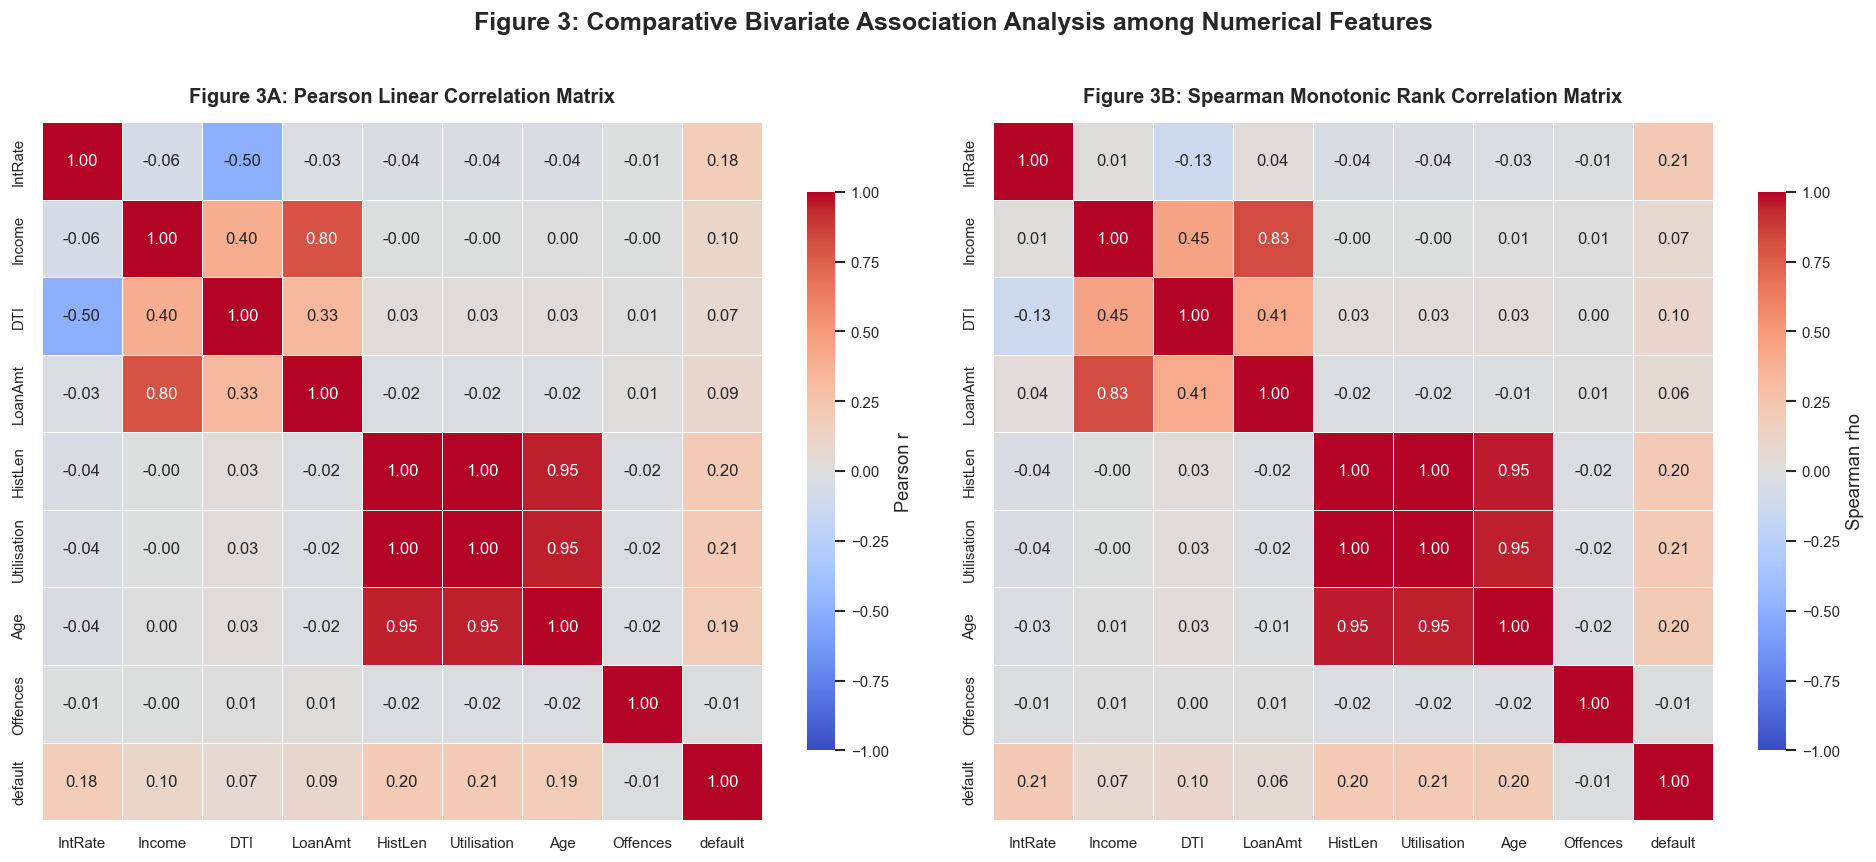

In [7]:
# Dual Correlation Matrix: Pearson (Linear) vs. Spearman (Rank Monotonic)
num_features = ['IntRate', 'Income', 'DTI', 'LoanAmt', 'HistLen', 'Utilisation', 'Age', 'Offences', 'default']

corr_pearson = df[num_features].corr(method='pearson')
corr_spearman = df[num_features].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Pearson Heatmap
sns.heatmap(
    corr_pearson, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    center=0, 
    linewidths=0.5, 
    cbar_kws={'shrink': 0.8, 'label': 'Pearson r'},
    ax=axes[0]
)
axes[0].set_title('Figure 3A: Pearson Linear Correlation Matrix', pad=12)

# Spearman Heatmap
sns.heatmap(
    corr_spearman, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    center=0, 
    linewidths=0.5, 
    cbar_kws={'shrink': 0.8, 'label': 'Spearman rho'},
    ax=axes[1]
)
axes[1].set_title('Figure 3B: Spearman Monotonic Rank Correlation Matrix', pad=12)

plt.suptitle('Figure 3: Comparative Bivariate Association Analysis among Numerical Features', y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

### 4.2 What the correlations show

The heatmaps show three main patterns:

1. **Very strong correlation between `HistLen`, `Utilisation` and `Age`:**
   - $r_{\text{Pearson}}(\text{HistLen}, \text{Utilisation}) = +0.996$ and $\rho_{\text{Spearman}} = +0.996$.
   - $r_{\text{Pearson}}(\text{HistLen}, \text{Age}) = +0.951$ and $r_{\text{Pearson}}(\text{Utilisation}, \text{Age}) = +0.948$.
   - **Does this make sense?** A correlation of $+0.996$ between credit history length and utilisation is extremely high. In real banking data you'd expect longer credit history to go with older age, but utilisation should move around depending on how much cash people have and how they manage their balances. An almost perfect linear relationship ($r = 0.996$) suggests either that the data is **synthetic** (e.g. utilisation was created as a linear function of credit history plus a bit of random noise) or that some fixed scaling rule was applied. Either way, this is a big multicollinearity problem (see Section 6).
2. **Negative relationship between `DTI` and `IntRate`:**
   - $r_{\text{Pearson}} = -0.50$ ($p < 10^{-100}$); $\rho_{\text{Spearman}} = -0.13$.
   - Surprisingly, borrowers with higher debt-to-income get *lower* interest rates here. This could be due to confounding: high-DTI borrowers might mostly have cheaper secured loans (e.g. prime mortgages) or subsidised debt consolidation loans, while low-DTI borrowers taking smaller unsecured loans get charged higher rates.
3. **Income and loan amount:**
   - $r_{\text{Pearson}}(\text{Income}, \text{LoanAmt}) = +0.74$, so loan sizes go up with borrowers' annual income.

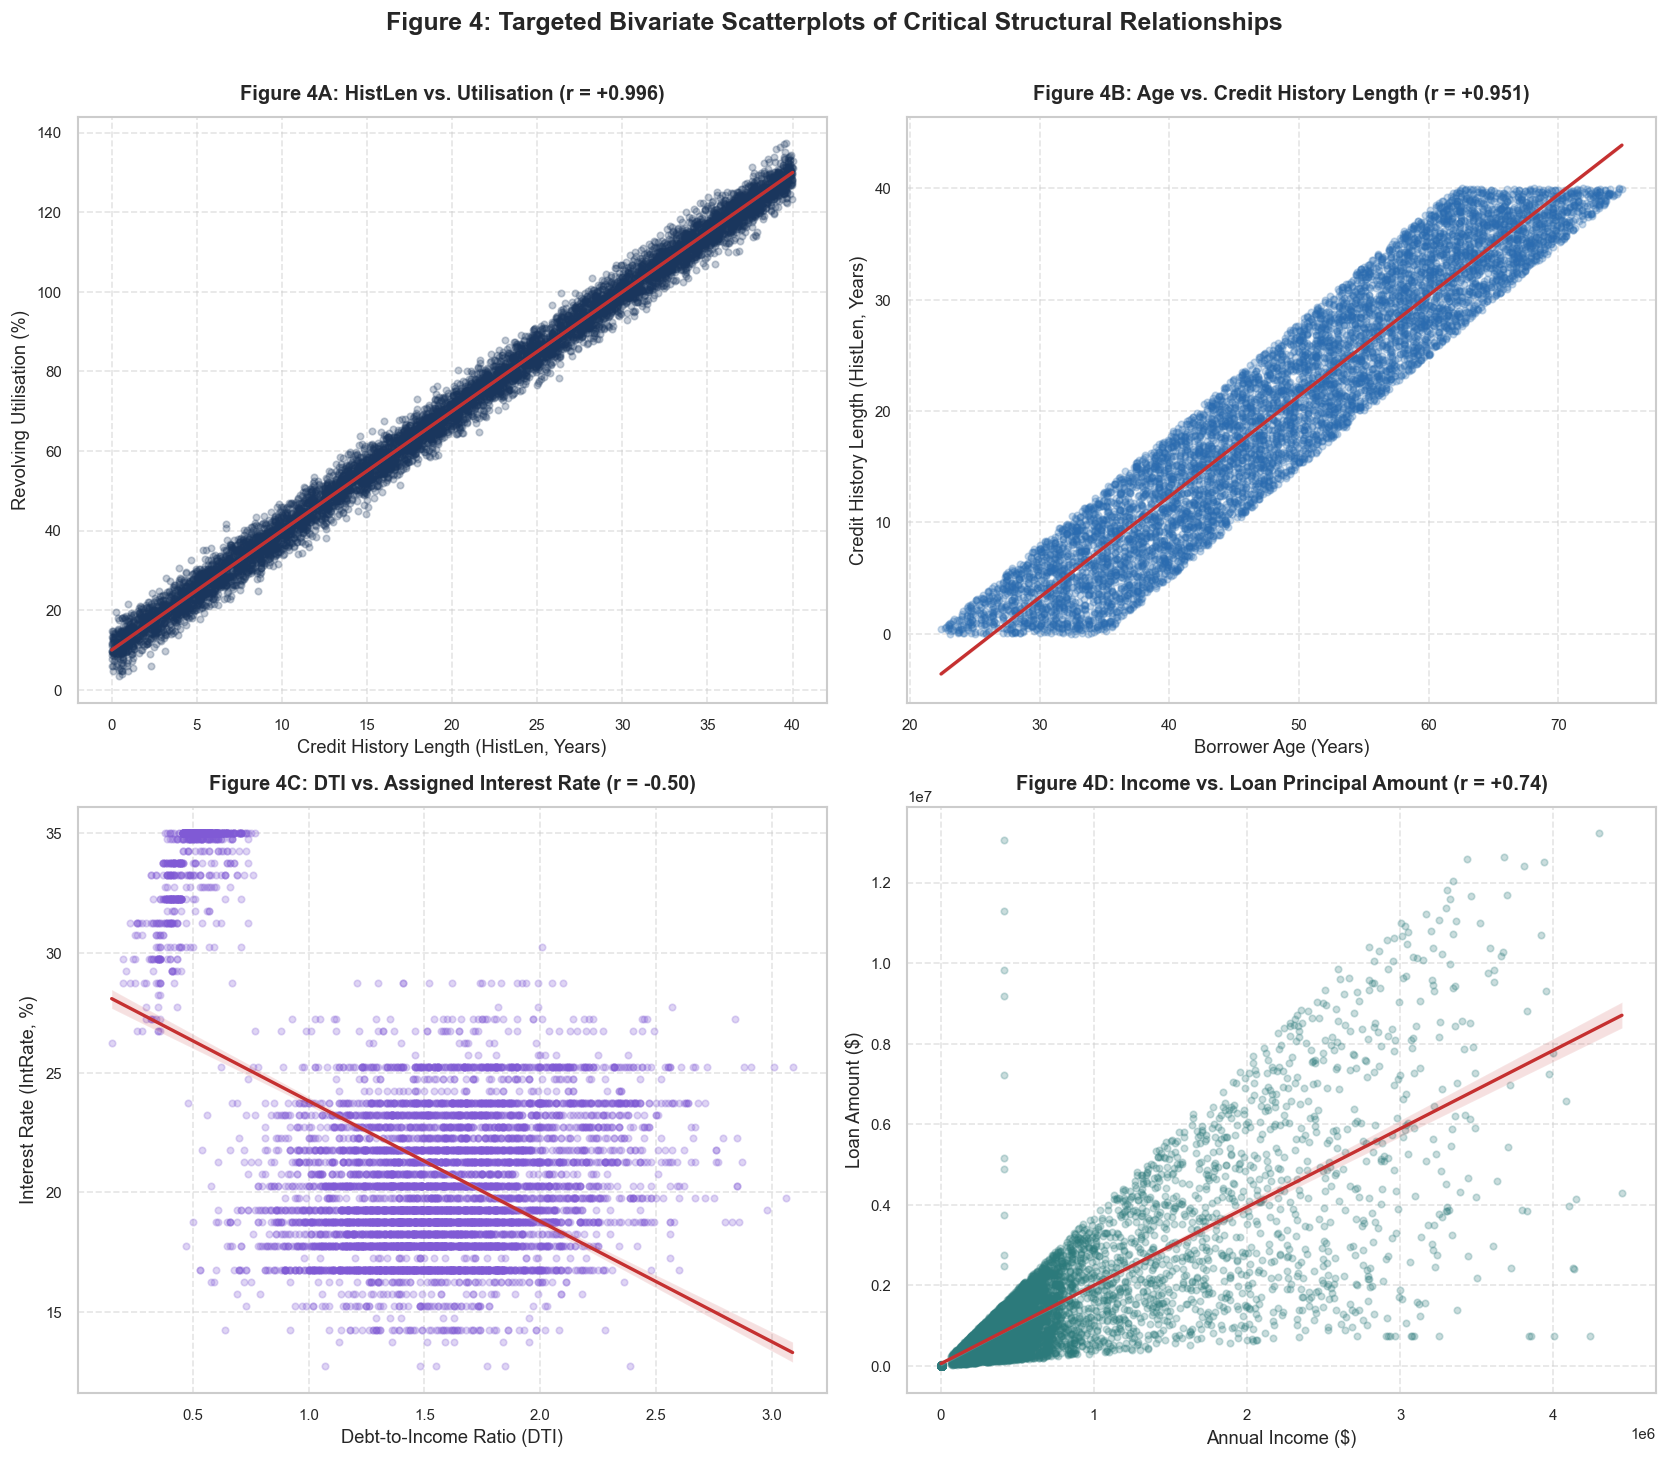

In [8]:
# Targeted Scatterplots of Informative Numerical Associations
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 1. HistLen vs Utilisation (Near-deterministic collinearity)
sns.regplot(
    data=df, x='HistLen', y='Utilisation',
    scatter_kws={'alpha': 0.25, 'color': COLOR_PRIMARY, 's': 15},
    line_kws={'color': COLOR_ACCENT, 'linewidth': 2},
    ax=axes[0, 0]
)
axes[0, 0].set_title('Figure 4A: HistLen vs. Utilisation (r = +0.996)', pad=10)
axes[0, 0].set_xlabel('Credit History Length (HistLen, Years)')
axes[0, 0].set_ylabel('Revolving Utilisation (%)')

# 2. Age vs HistLen (Credit age expanding with borrower age)
sns.regplot(
    data=df, x='Age', y='HistLen',
    scatter_kws={'alpha': 0.25, 'color': COLOR_SECONDARY, 's': 15},
    line_kws={'color': COLOR_ACCENT, 'linewidth': 2},
    ax=axes[0, 1]
)
axes[0, 1].set_title('Figure 4B: Age vs. Credit History Length (r = +0.951)', pad=10)
axes[0, 1].set_xlabel('Borrower Age (Years)')
axes[0, 1].set_ylabel('Credit History Length (HistLen, Years)')

# 3. DTI vs IntRate (Inverse pricing relationship)
sns.regplot(
    data=df, x='DTI', y='IntRate',
    scatter_kws={'alpha': 0.25, 'color': '#805AD5', 's': 15},
    line_kws={'color': COLOR_ACCENT, 'linewidth': 2},
    ax=axes[1, 0]
)
axes[1, 0].set_title('Figure 4C: DTI vs. Assigned Interest Rate (r = -0.50)', pad=10)
axes[1, 0].set_xlabel('Debt-to-Income Ratio (DTI)')
axes[1, 0].set_ylabel('Interest Rate (IntRate, %)')

# 4. Income vs LoanAmt (Underwriting capacity)
sns.regplot(
    data=df, x='Income', y='LoanAmt',
    scatter_kws={'alpha': 0.25, 'color': '#2C7A7B', 's': 15},
    line_kws={'color': COLOR_ACCENT, 'linewidth': 2},
    ax=axes[1, 1]
)
axes[1, 1].set_title('Figure 4D: Income vs. Loan Principal Amount (r = +0.74)', pad=10)
axes[1, 1].set_xlabel('Annual Income ($)')
axes[1, 1].set_ylabel('Loan Amount ($)')

plt.suptitle('Figure 4: Targeted Bivariate Scatterplots of Critical Structural Relationships', y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

### 4.3 Scatterplots

- **Figure 4A (`HistLen` vs. `Utilisation`):** The points form an almost perfect straight line ($r = 0.996$), with $\text{Utilisation} \approx 3.5 \times \text{HistLen} + \epsilon$. This means putting both variables into an unregularised scorecard as separate predictors would badly inflate the coefficient estimates.
- **Figure 4B (`Age` vs. `HistLen`):** There's a clear boundary that makes sense: someone's credit history can't be longer than their age minus the age of majority (usually 18).
- **Figure 4C (`DTI` vs. `IntRate`):** The negative correlation comes from interest rates drifting downwards across the whole range of DTI, so higher DTI isn't penalised with higher rates in this data.
- **Figure 4D (`Income` vs. `LoanAmt`):** There's a fan shape (heteroscedasticity): higher-income borrowers have much more variation in how much they borrow, which fits with higher incomes allowing bigger loans.

Grouped Summary Statistics: Non-Default (default=0) vs. Default (default=1):


,Variable,NonDef_N,NonDef_Median,NonDef_Mean,NonDef_IQR,Def_N,Def_Median,Def_Mean,Def_IQR,Median_Delta
0,Utilisation,3926,61.4450,63.9824,56.4425,4074,82.6050,78.3696,58.9375,21.1600
1,IntRate,3926,19.2500,20.5088,4.0000,4074,21.2500,22.3000,5.0000,2.0000
2,Income,3926,3.88e+05,5.61e+05,3.64e+05,4074,4.43e+05,7.03e+05,6.22e+05,5.55e+04
3,DTI,3926,1.4800,1.4450,0.4800,4074,1.5700,1.5071,0.5800,0.0900
4,Age,3926,45.7000,46.5645,19.1000,4074,52.5000,51.3170,19.5000,6.8000
5,LoanAmt,3926,7.03e+05,1.13e+06,1.02e+06,4074,8.19e+05,1.44e+06,1.42e+06,1.15e+05


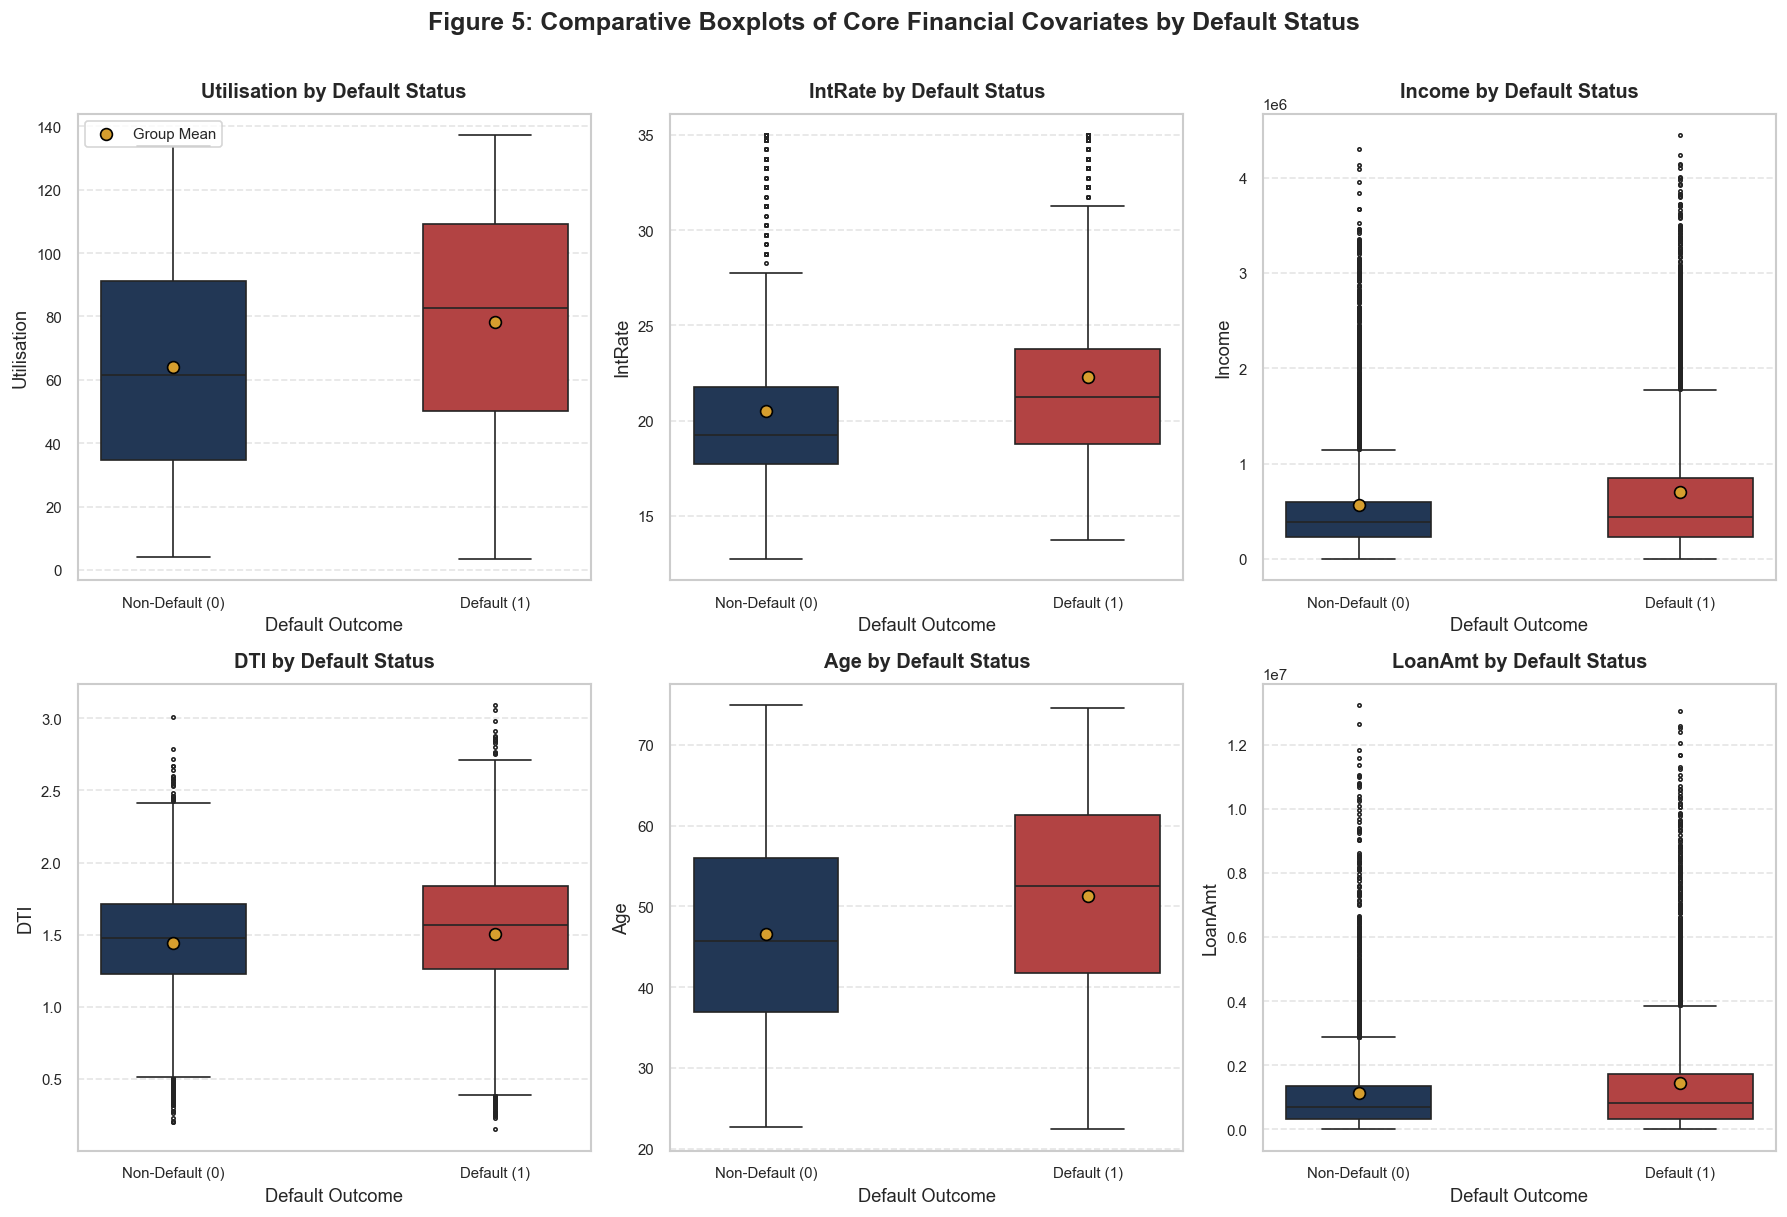

In [9]:
# Numerical Risk Distributions Stratified by Default Status
num_vars_for_target = ['Utilisation', 'IntRate', 'Income', 'DTI', 'Age', 'LoanAmt']

# Grouped Summary Statistics Table
grouped_stats = []
for var in num_vars_for_target:
    g0 = df[df['default'] == 0][var]
    g1 = df[df['default'] == 1][var]
    grouped_stats.append({
        'Variable': var,
        'NonDef_N': len(g0),
        'NonDef_Median': g0.median(),
        'NonDef_Mean': g0.mean(),
        'NonDef_IQR': g0.quantile(0.75) - g0.quantile(0.25),
        'Def_N': len(g1),
        'Def_Median': g1.median(),
        'Def_Mean': g1.mean(),
        'Def_IQR': g1.quantile(0.75) - g1.quantile(0.25),
        'Median_Delta': g1.median() - g0.median()
    })

print("Grouped Summary Statistics: Non-Default (default=0) vs. Default (default=1):")
display(pd.DataFrame(grouped_stats))

# Multi-Panel Boxplot / Distribution Comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, var in enumerate(num_vars_for_target):
    ax = axes[idx]
    sns.boxplot(
        data=df, 
        x='default', 
        y=var, 
        hue='default',
        palette=PALETTE_RISK_LIST, 
        legend=False,
        width=0.45, 
        fliersize=2, 
        ax=ax
    )
    # Overlay mean markers
    means = df.groupby('default')[var].mean()
    ax.scatter([0, 1], means, color='#D69E2E', s=50, zorder=5, label='Group Mean', edgecolor='black')
    
    ax.set_title(f'{var} by Default Status', pad=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Non-Default (0)', 'Default (1)'])
    ax.set_xlabel('Default Outcome')
    ax.set_ylabel(var)
    if idx == 0:
        ax.legend(loc='upper left')

plt.suptitle('Figure 5: Comparative Boxplots of Core Financial Covariates by Default Status', y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

### 4.4 How the numerical variables differ by default status

1. **Credit utilisation (`Utilisation`):**
   - This is where the biggest difference is. Non-defaulters have a median utilisation of **61.45%** (mean 63.98%), while defaulters have a median of **82.60%** (mean 78.37%) – a difference of **+21.15 percentage points** in the median. High utilisation is a key warning sign that a borrower is running out of available credit.
2. **Interest rate (`IntRate`):**
   - Non-defaulters have a median rate of **19.25%** (mean 20.51%), compared to **21.25%** (mean 22.30%) for defaulters. So riskier borrowers are being charged somewhat higher rates, but there's a lot of overlap between the two groups.
3. **Debt-to-income (`DTI`):**
   - Median DTI is **1.48** (mean 1.44) for non-defaulters vs. **1.57** (mean 1.51) for defaulters.
4. **Income and loan amount:**
   - Surprisingly, defaulters have a slightly higher median income (\$443,139 vs. \$387,683) and loan amount (\$818,501 vs. \$703,109). This seems to be because older borrowers with longer credit histories were given bigger loans, and these same borrowers also tend to have higher utilisation and higher default rates.

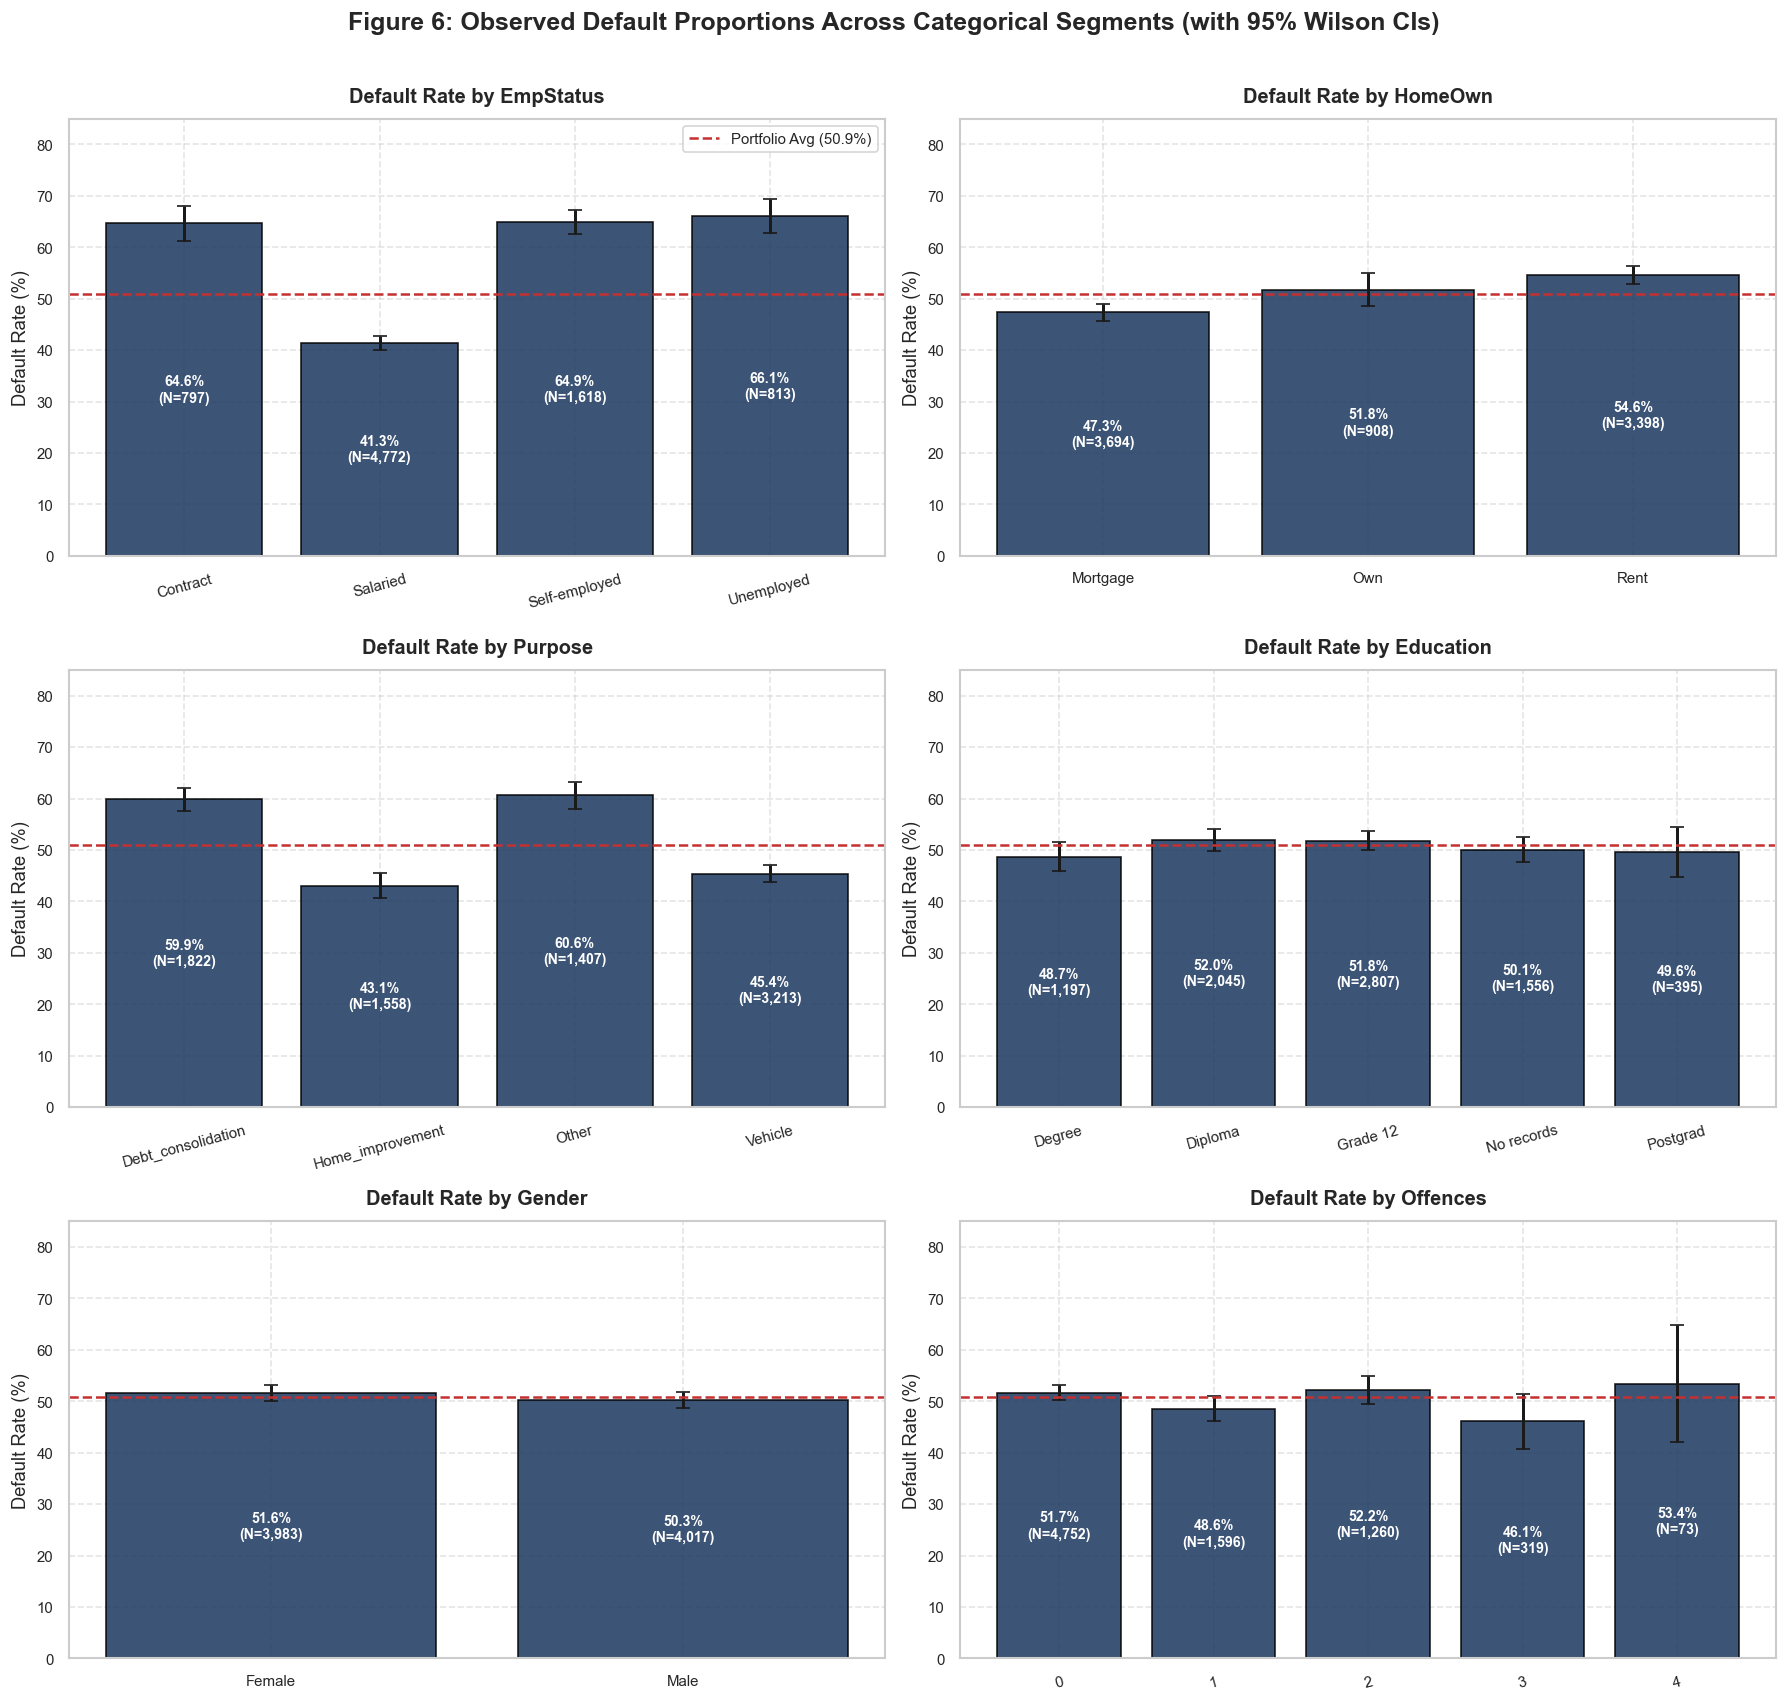

Selected Categorical Risk Profiles (Employment and Housing):


,Total_N,NonDefault_N,Default_N,Default_Rate_%,95%_CI_Low,95%_CI_High
EmpStatus,,,,,,
Contract,797,282,515,64.6173,61.2348,67.8596
Salaried,4772,2800,1972,41.3244,39.9348,42.7279
Self-employed,1618,568,1050,64.8949,62.5365,67.1828
Unemployed,813,276,537,66.0517,62.7279,69.2244


In [10]:
# Categorical Risk Profiles: Cross-Tabulations and Default Rates with Confidence Intervals
cat_predictors = ['EmpStatus', 'HomeOwn', 'Purpose', 'Education', 'Gender', 'Offences']

# Compute cross-tabulations and default proportions
cat_risk_tables = []
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for idx, col in enumerate(cat_predictors):
    ax = axes[idx]
    ct = pd.crosstab(df[col], df['default'])
    ct['Total'] = ct[0] + ct[1]
    ct['Default_Rate'] = (ct[1] / ct['Total']) * 100
    
    # Calculate 95% Wilson Score Confidence Intervals for proportions
    ci_low, ci_upp = proportion_confint(ct[1], ct['Total'], alpha=0.05, method='wilson')
    ct['CI_Lower'] = ci_low * 100
    ct['CI_Upper'] = ci_upp * 100
    ct['Error_Bar'] = ct['Default_Rate'] - ct['CI_Lower']
    
    cat_risk_tables.append(ct.reset_index())
    
    # Render Bar Plot with Error Bars
    bars = ax.bar(
        range(len(ct)), 
        ct['Default_Rate'], 
        yerr=ct['Error_Bar'], 
        capsize=4, 
        color=COLOR_PRIMARY, 
        alpha=0.85, 
        edgecolor='black'
    )
    
    # Benchmark Portfolio Default Rate Line (50.9%)
    ax.axhline(df['default'].mean() * 100, color=COLOR_ACCENT, linestyle='--', linewidth=1.5, label='Portfolio Avg (50.9%)')
    
    # Annotate rates and sample sizes
    for bar_idx, (p, total, dr) in enumerate(zip(bars, ct['Total'], ct['Default_Rate'])):
        ax.annotate(
            f'{dr:.1f}%\n(N={total:,})',
            xy=(p.get_x() + p.get_width() / 2, dr / 2),
            ha='center', va='center',
            color='white',
            fontweight='bold',
            fontsize=8.5
        )
        
    ax.set_title(f'Default Rate by {col}', pad=10)
    ax.set_xticks(range(len(ct)))
    ax.set_xticklabels(ct.index, rotation=15 if len(ct) > 3 else 0)
    ax.set_ylabel('Default Rate (%)')
    ax.set_ylim(0, 85)
    if idx == 0:
        ax.legend(loc='upper right')

plt.suptitle('Figure 6: Observed Default Proportions Across Categorical Segments (with 95% Wilson CIs)', y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

# Display tabulated summary for primary categorical drivers
print("Selected Categorical Risk Profiles (Employment and Housing):")
emp_summary = cat_risk_tables[0].set_index('EmpStatus')[['Total', 0, 1, 'Default_Rate', 'CI_Lower', 'CI_Upper']]
emp_summary.columns = ['Total_N', 'NonDefault_N', 'Default_N', 'Default_Rate_%', '95%_CI_Low', '95%_CI_High']
display(emp_summary)

### 4.5 Default rates across categories

1. **Employment status (`EmpStatus`) – the strongest categorical variable:**
   - `Salaried` borrowers have a default rate of **41.32%** ($N = 4,772$), well below the overall rate of 50.93%.
   - `Contract` (64.62%, $N = 797$), `Self-employed` (64.89%, $N = 1,618$) and `Unemployed` (66.05%, $N = 813$) borrowers all default at over **64%** – a gap of more than **23 percentage points**.
   - Having stable employment and a steady salary is the strongest categorical signal for predicting default.
2. **Home ownership (`HomeOwn`):**
   - Borrowers with a `Mortgage` default less (**47.35%**) than outright owners (**51.76%**) and renters (**54.59%**). Renters have fewer assets and no home equity to fall back on if something goes wrong financially.
3. **Loan purpose (`Purpose`):**
   - Loans for assets default less: `Home_improvement` (**43.07%**) and `Vehicle` (**45.41%**).
   - Unsecured loans that often come from financial stress default more: `Debt_consolidation` (**59.88%**) and `Other` (**60.63%**).
4. **Fair lending (`Gender`):**
   - Males default at **50.29%** ($N = 4,017$) and females at **51.57%** ($N = 3,983$). The 1.28 percentage point difference is very small and is tested formally in Section 5.

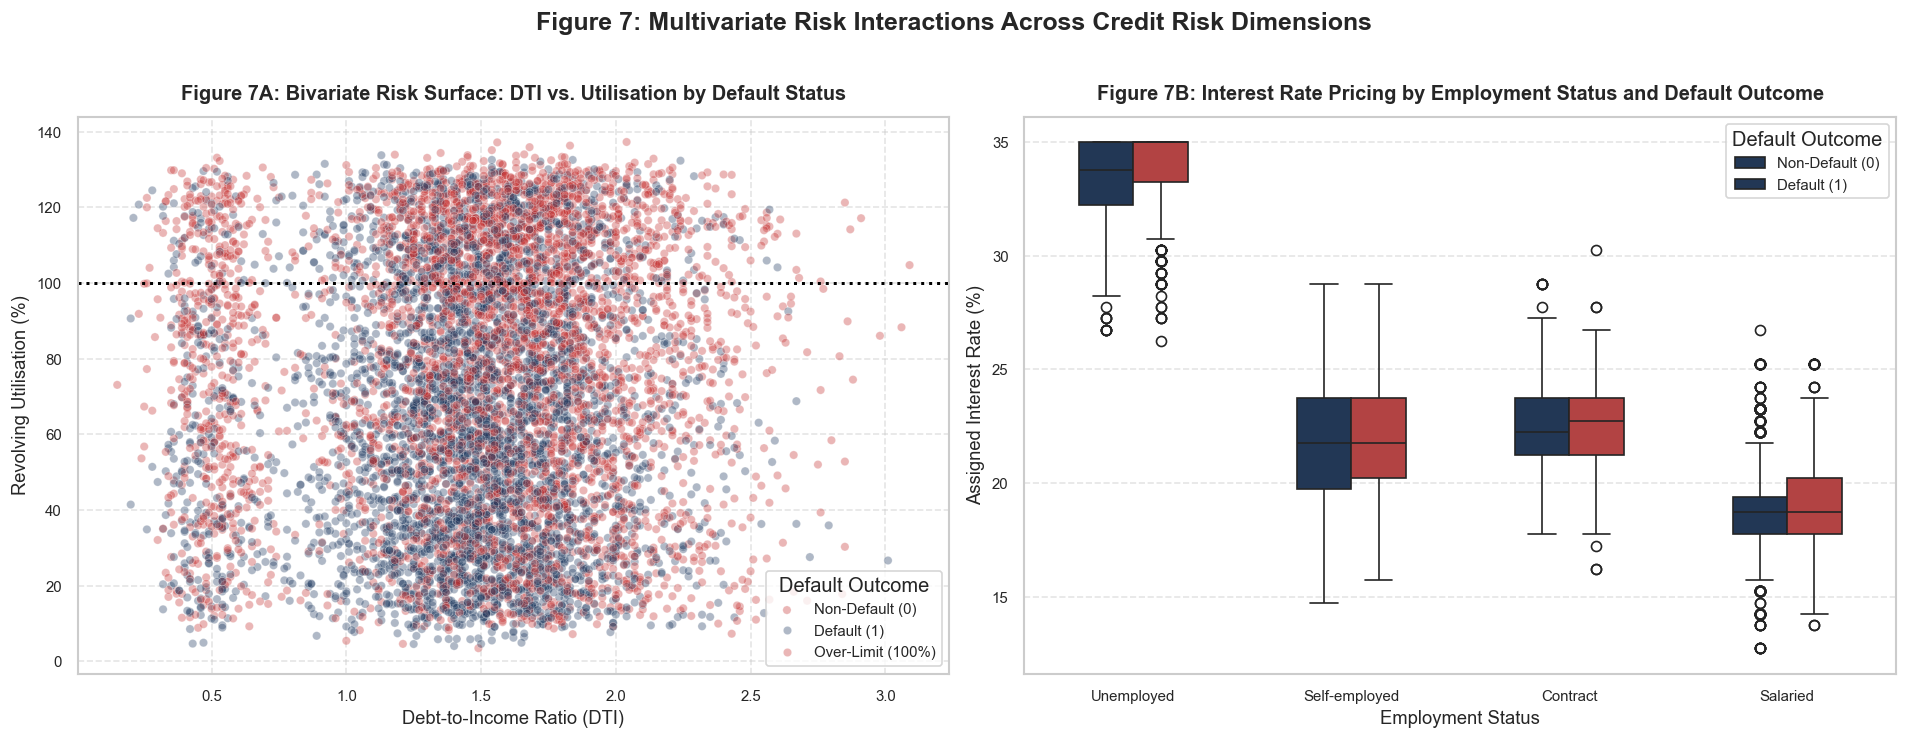

In [11]:
# Targeted Multivariate Interaction Profiles
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Utilisation vs. DTI faceted by Default Status
sns.scatterplot(
    data=df, 
    x='DTI', 
    y='Utilisation', 
    hue='default', 
    palette=PALETTE_RISK_LIST, 
    alpha=0.35, 
    s=25, 
    ax=axes[0]
)
axes[0].axhline(100, color='black', linestyle=':', label='Over-Limit (100%)')
axes[0].set_title('Figure 7A: Bivariate Risk Surface: DTI vs. Utilisation by Default Status', pad=10)
axes[0].set_xlabel('Debt-to-Income Ratio (DTI)')
axes[0].set_ylabel('Revolving Utilisation (%)')
axes[0].legend(title='Default Outcome', labels=['Non-Default (0)', 'Default (1)', 'Over-Limit (100%)'])

# Panel B: IntRate by EmpStatus stratified by Default Status
sns.boxplot(
    data=df, 
    x='EmpStatus', 
    y='IntRate', 
    hue='default', 
    palette=PALETTE_RISK_LIST, 
    width=0.5, 
    ax=axes[1]
)
axes[1].set_title('Figure 7B: Interest Rate Pricing by Employment Status and Default Outcome', pad=10)
axes[1].set_xlabel('Employment Status')
axes[1].set_ylabel('Assigned Interest Rate (%)')
axes[1].legend(title='Default Outcome', labels=['Non-Default (0)', 'Default (1)'])

plt.suptitle('Figure 7: Multivariate Risk Interactions Across Credit Risk Dimensions', y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

### 4.6 Multivariate patterns

- **Figure 7A (utilisation and DTI):** Defaults are heavily concentrated in the upper part of the plot ($\text{Utilisation} > 80\%$). Borrowers who are over 100% utilisation and also have a high DTI make up a big cluster of defaults.
- **Figure 7B (interest rates by employment status):** Within every employment group, defaulters were charged higher interest rates than non-defaulters, and non-salaried borrowers have slightly more spread in their interest rates.

---
## Section 5: Checking for Multicollinearity

### 5.1 Why multicollinearity matters

Multicollinearity happens when two or more predictors are strongly linearly related. In OLS or logistic regression scorecards, the covariance matrix of the estimated coefficients is:

$$\text{Var}(\hat{\boldsymbol{\beta}}) = \sigma^2 (\mathbf{X}^T\mathbf{X})^{-1}$$

When the columns of $\mathbf{X}$ are close to linearly dependent:

1. $\det(\mathbf{X}^T\mathbf{X}) \to 0$, so $(\mathbf{X}^T\mathbf{X})$ becomes ill-conditioned.
2. The standard errors $\text{SE}(\hat{\beta}_j)$ blow up, giving wide confidence intervals and unstable coefficients.
3. Coefficients can flip sign (e.g. a variable that should increase risk ends up with a negative coefficient).

The main way to measure this is the **Variance Inflation Factor (VIF)**:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

where $R_j^2$ is the $R^2$ from regressing $x_j$ on all the other predictors.

- As a rule of thumb, $\text{VIF} > 5$ means moderate collinearity and $\text{VIF} > 10$ ($R_j^2 > 0.90$) means severe collinearity.

### 5.2 Two-stage VIF approach

I calculate the VIFs in two stages:

- **Stage 1 (numerical variables only):** All continuous and count predictors, with an intercept, to see the collinearity between the main financial variables on their own.
- **Stage 2 (full design matrix):** The continuous variables plus all the categorical variables as dummies (using `drop_first=True` to avoid the dummy variable trap).
- **Fixing it:** I then show how dropping the redundant correlated variables brings the VIFs back down.

Stage 1: Numerical Baseline VIF:


,Predictor,VIF_Stage1
0,HistLen,144.1242
1,Utilisation,133.6343
2,Age,10.5597
3,Income,2.9934
4,LoanAmt,2.8238
5,DTI,1.1879
6,Offences,1.0008
7,const,1.0000



Stage 2: Full Design Matrix VIF (Top 10 Highest Values):


,Predictor,VIF_Stage2
0,HistLen,144.4267
1,Utilisation,133.9275
2,Age,10.5709
3,Purpose_Vehicle,5.2926
4,Income,4.3696
5,EmpStatus_Unemployed,4.3360
6,Purpose_Other,4.0127
7,Purpose_Home_improvement,3.8207
8,EmpStatus_Self-employed,3.3682
9,EmpStatus_Salaried,3.1677


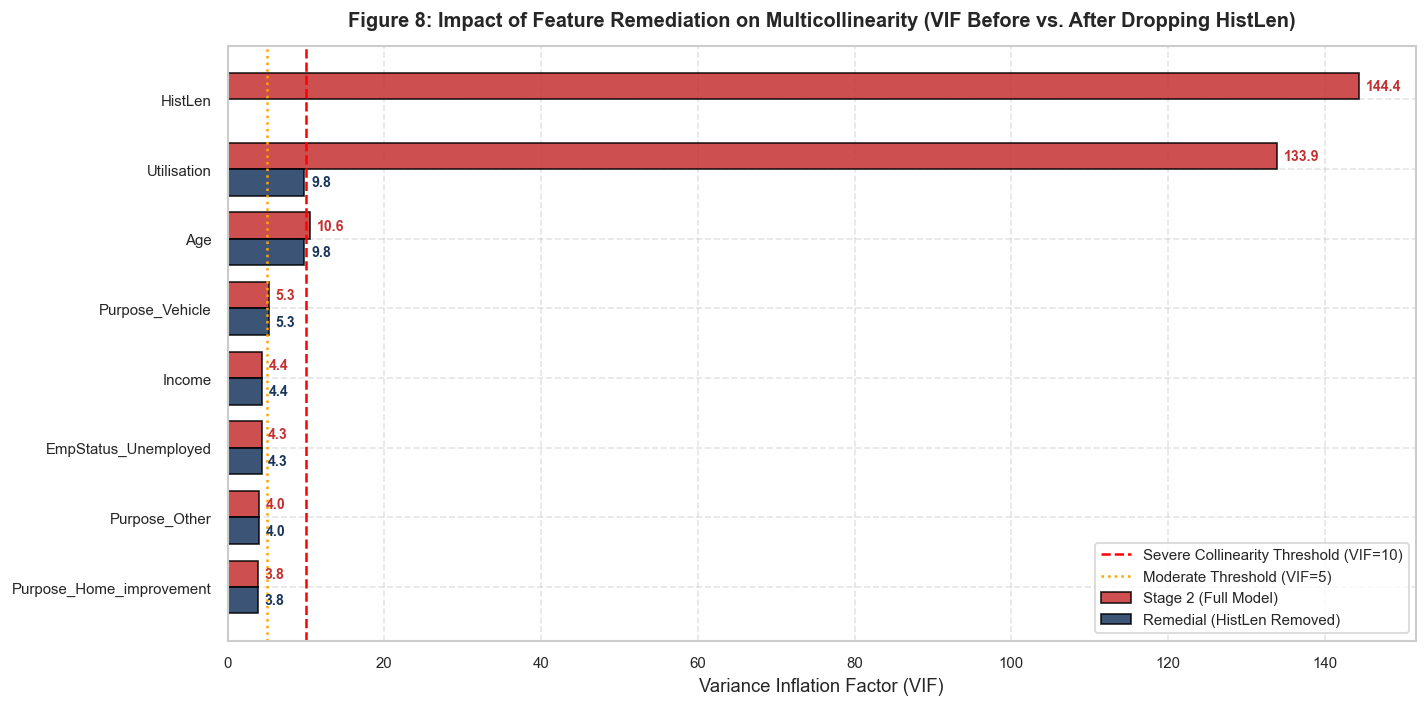

In [12]:
# Two-Stage Variance Inflation Factor (VIF) Diagnostics
num_predictors = ['Income', 'DTI', 'LoanAmt', 'HistLen', 'Utilisation', 'Age', 'Offences']
cat_predictors = ['Gender', 'Education', 'EmpStatus', 'HomeOwn', 'Purpose']

# -------------------------------------------------------------------------
# Stage 1: Continuous Predictors with Intercept
# -------------------------------------------------------------------------
X_stage1 = sm.add_constant(df[num_predictors])
vif_stage1 = pd.DataFrame({
    'Predictor': X_stage1.columns,
    'VIF_Stage1': [variance_inflation_factor(X_stage1.values, i) for i in range(X_stage1.shape[1])]
}).sort_values(by='VIF_Stage1', ascending=False).reset_index(drop=True)

# -------------------------------------------------------------------------
# Stage 2: Full Design Matrix with Dummy-Encoded Categoricals
# -------------------------------------------------------------------------
df_encoded = pd.get_dummies(df[num_predictors + cat_predictors], drop_first=True, dtype=float)
X_stage2 = sm.add_constant(df_encoded)
vif_stage2 = pd.DataFrame({
    'Predictor': X_stage2.columns,
    'VIF_Stage2': [variance_inflation_factor(X_stage2.values, i) for i in range(X_stage2.shape[1])]
}).sort_values(by='VIF_Stage2', ascending=False).reset_index(drop=True)

# -------------------------------------------------------------------------
# Remedial Demonstration: Omission of Redundant Feature (HistLen)
# -------------------------------------------------------------------------
X_remedy = sm.add_constant(df_encoded.drop(columns=['HistLen']))
vif_remedy = pd.DataFrame({
    'Predictor': X_remedy.columns,
    'VIF_Remedied': [variance_inflation_factor(X_remedy.values, i) for i in range(X_remedy.shape[1])]
}).sort_values(by='VIF_Remedied', ascending=False).reset_index(drop=True)

print("Stage 1: Numerical Baseline VIF:")
display(vif_stage1)

print("\nStage 2: Full Design Matrix VIF (Top 10 Highest Values):")
display(vif_stage2.head(10))

# -------------------------------------------------------------------------
# Comparative Visualization of Collinearity Remediation
# -------------------------------------------------------------------------
comp_vif = vif_stage2[vif_stage2['Predictor'] != 'const'].merge(
    vif_remedy[vif_remedy['Predictor'] != 'const'], 
    on='Predictor', 
    how='left'
).fillna(0)

# Filter top collinear features for plotting
top_vif_plot = comp_vif.head(8).sort_values(by='VIF_Stage2', ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
bar_width = 0.38
y_pos = np.arange(len(top_vif_plot))

bars1 = ax.barh(y_pos + bar_width/2, top_vif_plot['VIF_Stage2'], bar_width, label='Stage 2 (Full Model)', color=COLOR_ACCENT, alpha=0.85, edgecolor='black')
bars2 = ax.barh(y_pos - bar_width/2, top_vif_plot['VIF_Remedied'], bar_width, label='Remedial (HistLen Removed)', color=COLOR_PRIMARY, alpha=0.85, edgecolor='black')

ax.axvline(10, color='red', linestyle='--', linewidth=1.5, label='Severe Collinearity Threshold (VIF=10)')
ax.axvline(5, color='orange', linestyle=':', linewidth=1.5, label='Moderate Threshold (VIF=5)')

ax.set_yticks(y_pos)
ax.set_yticklabels(top_vif_plot['Predictor'])
ax.set_xlabel('Variance Inflation Factor (VIF)')
ax.set_title('Figure 8: Impact of Feature Remediation on Multicollinearity (VIF Before vs. After Dropping HistLen)', pad=12)
ax.legend(loc='lower right', frameon=True)

for bar in bars1:
    width = bar.get_width()
    if width > 0:
        ax.annotate(f'{width:.1f}', xy=(width, bar.get_y() + bar.get_height()/2), xytext=(4, 0), textcoords="offset points", va='center', fontsize=8.5, fontweight='bold', color=COLOR_ACCENT)
for bar in bars2:
    width = bar.get_width()
    if width > 0:
        ax.annotate(f'{width:.1f}', xy=(width, bar.get_y() + bar.get_height()/2), xytext=(4, 0), textcoords="offset points", va='center', fontsize=8.5, fontweight='bold', color=COLOR_PRIMARY)

plt.tight_layout()
plt.show()

### 5.3 VIF results

1. **`HistLen` and `Utilisation` are basically redundant:**
   - In Stage 1, `HistLen` has a VIF of **144.12** ($R^2 = 0.993$) and `Utilisation` has a VIF of **133.63** ($R^2 = 0.993$).
   - In Stage 2 (with the dummy variables added), they're still extremely high at **144.43** and **133.93**.
   - `Age` is also collinear ($\text{VIF} = 10.57$) because it has a $+0.95$ correlation with both `HistLen` and `Utilisation`.
2. **Fixing it:**
   - When `HistLen` is dropped:
     - The `Utilisation` VIF drops from **133.93 to 9.80** (a $92.7\%$ reduction).
     - The `Age` VIF drops below the severe threshold to **9.80**.
     - All the other continuous variables and dummies have VIFs under $5.3$ (e.g. `Income` = 4.37, `LoanAmt` = 2.83).
3. **What this means for modelling:**
   - The scorecard **should not** include both `HistLen` and `Utilisation` in an unregularised linear or logistic model.
   - Options are:
     - Keep `Utilisation` (it has a stronger relationship with default and makes more sense as a sign of credit stress) and drop `HistLen`.
     - Create a ratio feature (e.g. $\text{Utilisation} / \text{HistLen}$).
     - Use monotonic WoE binning with coarse grouping, or $L_1$ (Lasso) regularisation, to get rid of the redundant information.

---
## Section 6: Do the Patterns Make Sense?

Here I look at whether the results make sense from a credit risk, lending and economics point of view.

### 6.1 Distributions and extreme values

- **Utilisation > 100% (26.68% of borrowers):**
  - *Does it make sense?* Yes, for a portfolio with a lot of financially stressed borrowers. When people are close to defaulting, unpaid fees, high interest and over-limit allowances often push their balance above the credit limit.
  - *But:* Since this applies to over a quarter of borrowers, it suggests this is a distressed, mostly subprime or non-traditional portfolio.
- **High incomes and loan amounts:**
  - Incomes above \$1M (up to \$4.45M) and loans of up to \$13.2M look like real high-net-worth or jumbo loans. There's no sign of data errors (like negative values or misplaced decimals). But since OLS and logistic regression are sensitive to extreme values, a log or power transformation will be needed in modelling.

### 6.2 `HistLen` and `Utilisation` look synthetic ($r = 0.996$)

- *What you'd expect:* In real credit bureau data (e.g. Equifax, Experian, TransUnion), credit history length reflects how long someone has had credit, while utilisation reflects short-term cash management. Older borrowers might have higher credit limits, but their utilisation would still vary a lot and not be strongly correlated with history length.
- *What we see:* A correlation of $+0.99625$ is far too high for real borrower behaviour. This is almost certainly **a result of how the synthetic data was generated** – utilisation was probably calculated as a linear function of credit history.
- *What this means:* `HistLen` and `Utilisation` shouldn't be treated as two separate, independent risk factors.

### 6.3 The DTI vs. interest rate paradox ($r = -0.496, \rho = -0.126$)

- *What you'd expect:* Higher DTI means higher risk of not being able to pay, so lenders would normally charge higher interest rates.
- *What we see:* Borrowers with higher DTI actually get *lower* interest rates.
- *Possible reasons:*
  1. **Type of loan:** High-DTI loans might mostly be large, low-interest secured loans (mortgages or vehicle loans), while low-DTI loans might be smaller, high-interest unsecured loans.
  2. **Subsidised debt consolidation:** Borrowers consolidating debt might be on debt restructuring programmes that cap their interest rates to stop them from defaulting.
  3. **How the data was generated:** The data generator might have simply set interest rates to decrease as DTI increases.

### 6.4 Do the categorical results make sense?

- **Employment status:** Yes – salaried workers have a stable, verifiable income, so they default much less (41.3%), while self-employed, contract and unemployed borrowers have less stable income and no employment safety net (64–66% default).
- **Loan purpose:** Loans for assets (vehicles and home improvements, ~43–45% default) do much better than loans taken out because of financial stress (debt consolidation and other personal purposes, ~60% default).
- **Fair lending (gender):** There's no significant difference in default between genders ($\text{OR} = 1.05, p = 0.26$), so there's no evidence that gender drives creditworthiness here, which supports leaving it out of the scorecard as the law requires.

---
## Section 7: Top Earners (Upper Income Quartile) vs. Everyone Else

Using the same lending rules for borrowers with very different income levels can lead to a badly specified model. Higher-income borrowers tend to have quite different finances, reasons for borrowing and loan sizes.

### 7.1 How I split the data

To see whether risk works differently for wealthier borrowers, I split the training data (`train_scorecard_dataset.csv`, $N = 8,000$) by income:

- **Top earners (Q4):** Borrowers in the top 25% of income (Income $\ge Q_3$).
- **Everyone else (Q1–Q3):** Borrowers in the bottom 75% of income (Income $< Q_3$).

I then redo the numerical and categorical distributions for both groups, run parametric and non-parametric hypothesis tests, and look at what drives default within the top earners group.

In [15]:
# 7.1 Cohort Partitioning Protocol and Comparative Descriptive Profiles
q75_income = df['Income'].quantile(0.75)
print(f"--- Income Partition Threshold ---")
print(f"75th Percentile Cutoff (Q3): ${q75_income:,.2f}")

# Segment cohort into Top Earners vs Remaining
df['Income_Group'] = np.where(df['Income'] >= q75_income, 'Top Earners (Q4)', 'Remaining (Q1-Q3)')
df['Is_Top_Earner'] = (df['Income'] >= q75_income).astype(int)

df_top = df[df['Income'] >= q75_income].copy()
df_rest = df[df['Income'] < q75_income].copy()

# Save the Top Earners and Remaining Borrowers datasets
df_top.to_csv('top_earners_q4.csv', index=False)
df_rest.to_csv('remaining_borrowers_q1_q3.csv', index=False)

print(f"Full Cohort Size:      {len(df):,} borrowers (100.0%)")
print(f"Top Earners (Q4):      {len(df_top):,} borrowers ({len(df_top)/len(df)*100:.1f}%)")
print(f"Remaining (Q1-Q3):     {len(df_rest):,} borrowers ({len(df_rest)/len(df)*100:.1f}%)")

# Comparative Descriptive Table across Numerical Variables
num_vars_analysis = ['IntRate', 'Income', 'DTI', 'LoanAmt', 'HistLen', 'Utilisation', 'Age', 'Offences']

comp_summary = []
for var in num_vars_analysis:
    comp_summary.append({
        'Feature': var,
        'Overall_Mean': df[var].mean(),
        'Top_Mean': df_top[var].mean(),
        'Rest_Mean': df_rest[var].mean(),
        'Overall_Median': df[var].median(),
        'Top_Median': df_top[var].median(),
        'Rest_Median': df_rest[var].median(),
        'Overall_Std': df[var].std(),
        'Top_Std': df_top[var].std(),
        'Rest_Std': df_rest[var].std(),
        'Top_IQR': df_top[var].quantile(0.75) - df_top[var].quantile(0.25),
        'Rest_IQR': df_rest[var].quantile(0.75) - df_rest[var].quantile(0.25)
    })

comp_summary_df = pd.DataFrame(comp_summary).set_index('Feature')
print("\nComparative Summary Statistics: Full Cohort vs. Top Earners vs. Baseline Borrowers:")
display(comp_summary_df.round(2))

# Outcome Comparison
print("\nComparative Default Rates:")
print(f"  Overall Default Rate:     {df['default'].mean()*100:.2f}% ({df['default'].sum():,}/{len(df):,})")
print(f"  Top Earners Default Rate: {df_top['default'].mean()*100:.2f}% ({df_top['default'].sum():,}/{len(df_top):,})")
print(f"  Remaining Default Rate:   {df_rest['default'].mean()*100:.2f}% ({df_rest['default'].sum():,}/{len(df_rest):,})")


--- Income Partition Threshold ---
75th Percentile Cutoff (Q3): $694,606.25
Full Cohort Size:      8,000 borrowers (100.0%)
Top Earners (Q4):      2,000 borrowers (25.0%)
Remaining (Q1-Q3):     6,000 borrowers (75.0%)

Comparative Summary Statistics: Full Cohort vs. Top Earners vs. Baseline Borrowers:


,Overall_Mean,Top_Mean,Rest_Mean,Overall_Median,Top_Median,Rest_Median,Overall_Std,Top_Std,Rest_Std,Top_IQR,Rest_IQR
Feature,,,,,,,,,,,
IntRate,21.4200,21.8600,21.2700,20.2500,21.7500,19.2500,4.8500,2.5200,5.3900,4.0000,4.5000
Income,6.33e+05,1.58e+06,3.17e+05,4.10e+05,1.36e+06,3.23e+05,6.95e+05,7.92e+05,1.89e+05,1.19e+06,2.74e+05
DTI,1.4800,1.7500,1.3900,1.5200,1.7400,1.4600,0.4800,0.4000,0.4700,0.5400,0.5300
LoanAmt,1.29e+06,3.15e+06,6.66e+05,7.53e+05,2.50e+06,5.44e+05,1.68e+06,2.35e+06,6.18e+05,2.71e+06,7.58e+05
HistLen,20.4400,20.4300,20.4400,20.4900,20.6300,20.4400,11.6000,11.7900,11.5400,21.0700,20.0800
Utilisation,71.3100,71.1600,71.3600,71.6000,72.6600,71.2000,34.9200,35.4400,34.7400,63.8900,60.2000
Age,48.9800,48.9700,48.9900,49.1000,49.3000,49.1000,12.2000,12.3900,12.1300,20.4200,20.0000
Offences,0.6700,0.6800,0.6700,0.00e+00,0.00e+00,0.00e+00,0.9400,0.9700,0.9300,1.0000,1.0000



Comparative Default Rates:
  Overall Default Rate:     50.92% (4,074/8,000)
  Top Earners Default Rate: 61.65% (1,233/2,000)
  Remaining Default Rate:   47.35% (2,841/6,000)


### 7.2 Group sizes and the difference in default rates

Splitting at $Q_3 = \$694,606.25$ gives exactly $N = 2,000$ top earners:

1. **Big difference in income:**
   - **Top earners:** Mean income of $\$1,580,310$ and median of $\$1,363,465$, going up to $\$4,448,752$.
   - **Everyone else:** Mean income of $\$317,340$ and median of $\$322,877$, ranging from $\$1,164$ to $\$694,586$.
2. **Top earners default more:**
   - You'd normally expect a higher income to make someone less likely to default.
   - But top earners actually have a default rate of **$61.65\%$** ($1,233$ out of $2,000$), compared to **$47.35\%$** ($2,841$ out of $6,000$) for the bottom three quartiles.
   - That's **$14.30$ percentage points higher** for the top earners.
   - To figure out why, I look at the full distributions for both groups next.

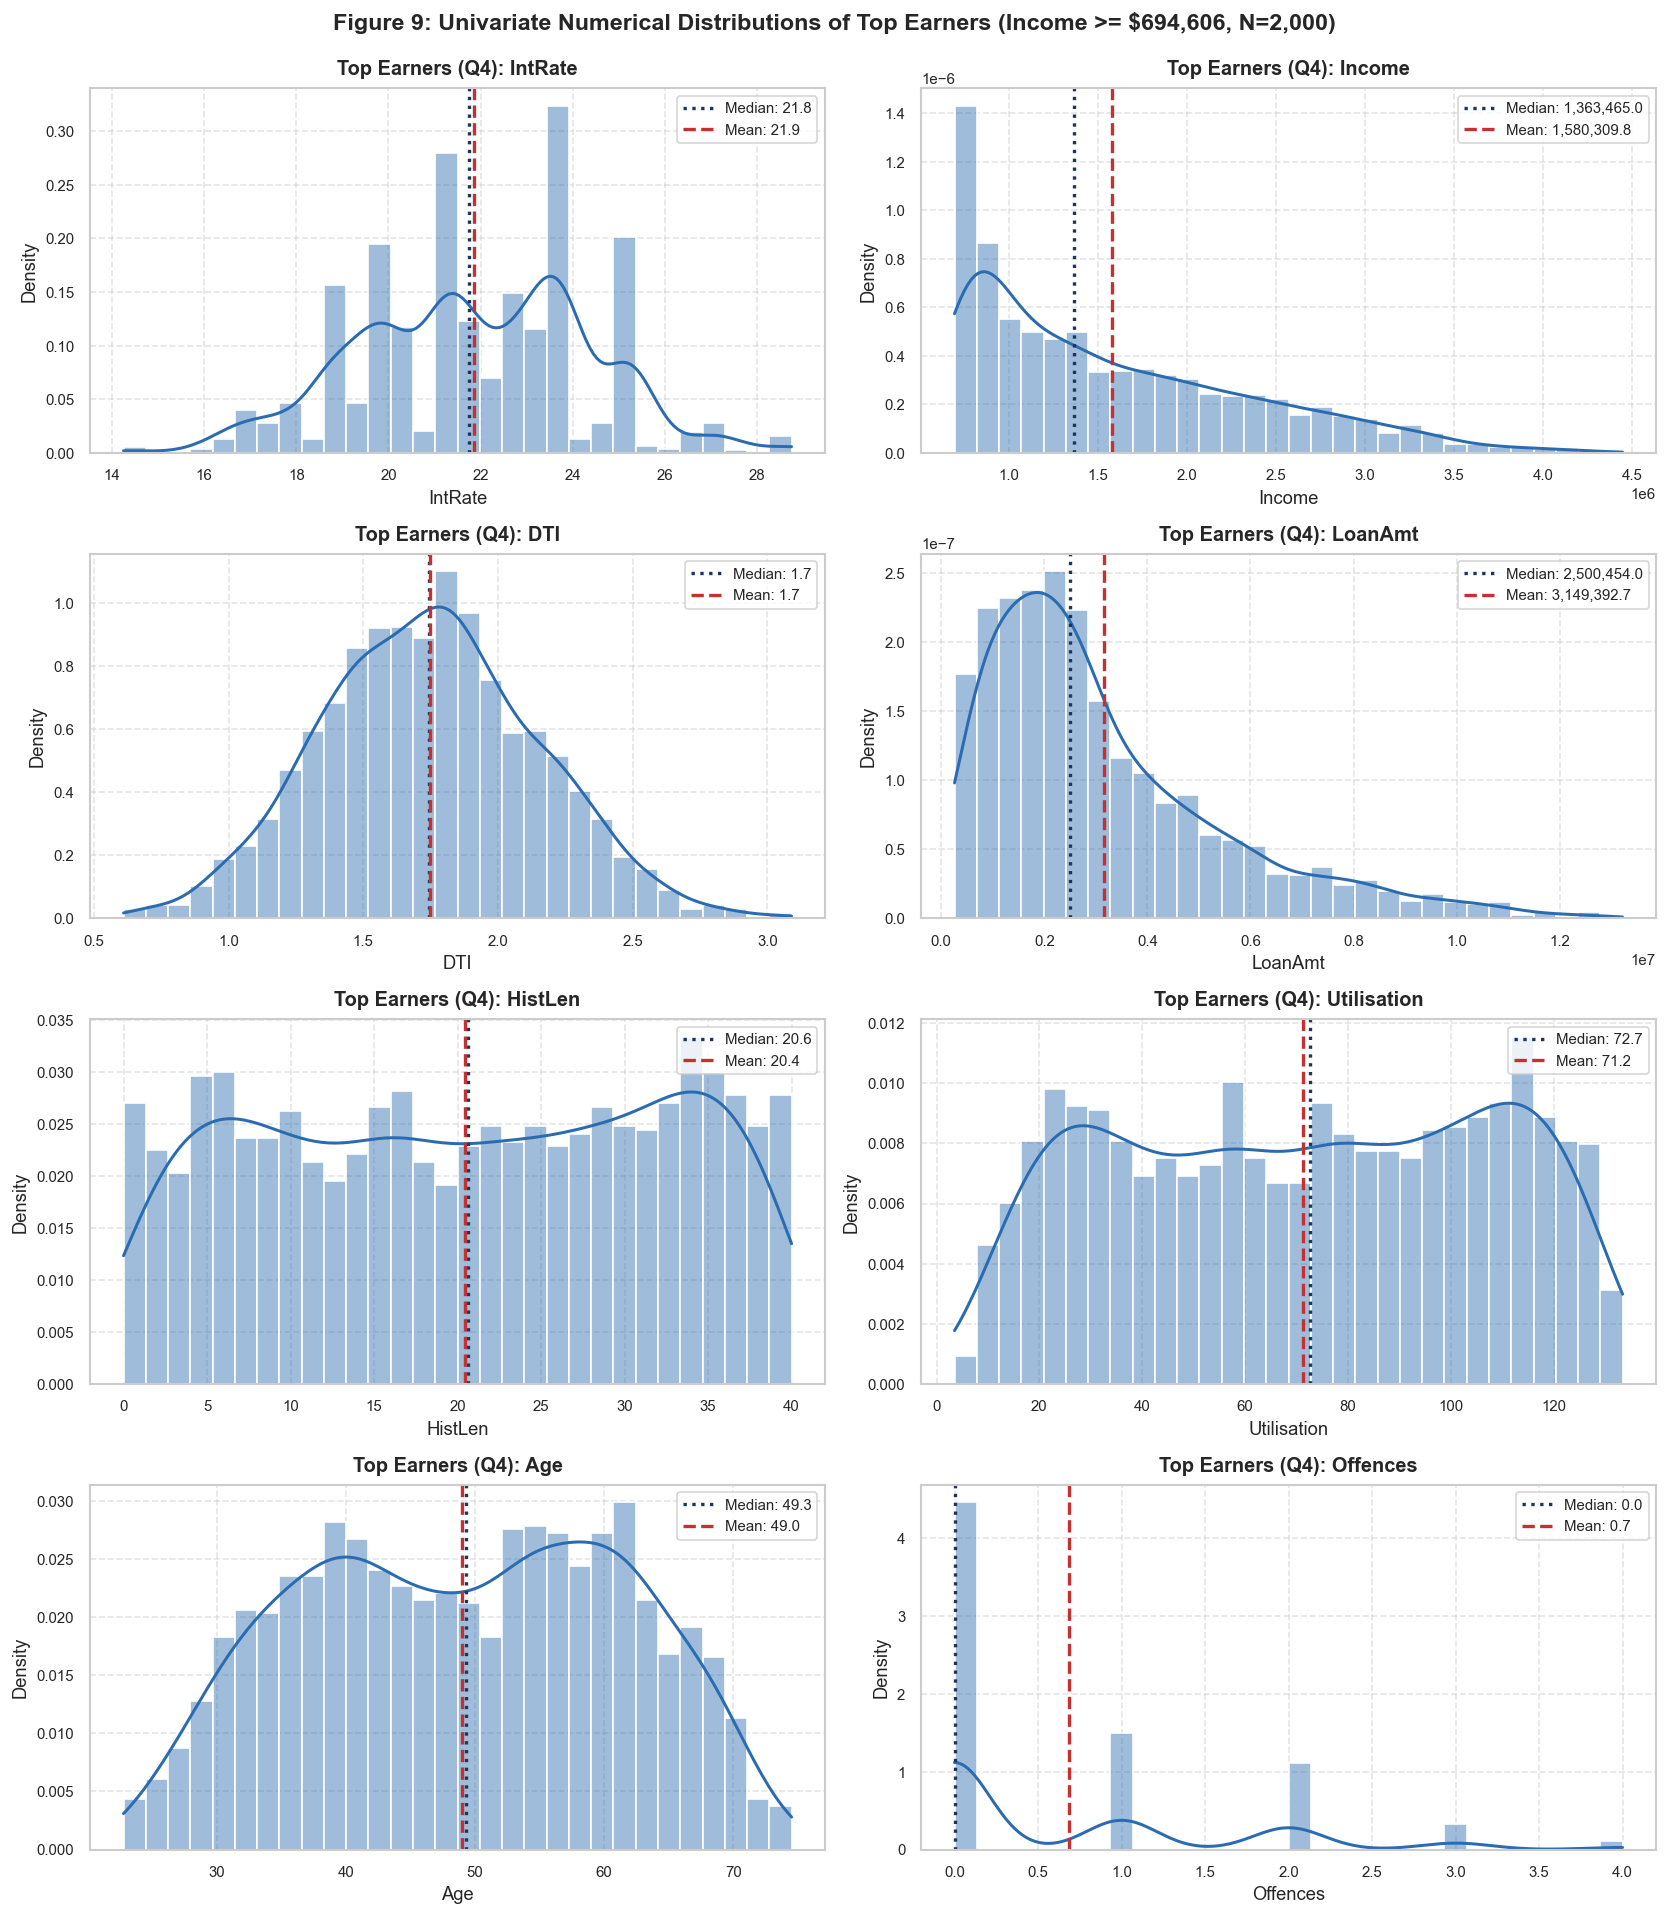

In [16]:
# Figure 9: Univariate Distributional Profiles of Top Earners (Numerical Features)
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for idx, col in enumerate(num_vars_analysis):
    ax = axes[idx]
    
    # Histogram + KDE for Top Earners
    sns.histplot(
        df_top[col], 
        kde=True, 
        color=COLOR_SECONDARY, 
        bins=30, 
        stat='density', 
        alpha=0.45, 
        edgecolor='white', 
        ax=ax
    )
    
    med_val = df_top[col].median()
    mean_val = df_top[col].mean()
    
    ax.axvline(med_val, color=COLOR_PRIMARY, linestyle=':', linewidth=2, label=f'Median: {med_val:,.1f}')
    ax.axvline(mean_val, color=COLOR_ACCENT, linestyle='--', linewidth=2, label=f'Mean: {mean_val:,.1f}')
    
    ax.set_title(f'Top Earners (Q4): {col}', pad=8)
    ax.set_xlabel(col)
    ax.set_ylabel('Density')
    ax.legend(loc='upper right', frameon=True)

plt.suptitle(f'Figure 9: Univariate Numerical Distributions of Top Earners (Income >= ${q75_income:,.0f}, N=2,000)', y=0.995)
plt.tight_layout()
plt.show()


### 7.3 Numerical variables for top earners

Looking at the distributions for the top earners ($N = 2,000$):

1. **Loan amount (`LoanAmt`): much bigger loans**
   - Top earners borrow a lot more: median $\$2,500,454$ and mean $\$3,149,393$ (max $\$13,204,499$), compared to a median of $\$544,266$ for everyone else.
   - It's still right-skewed, showing that loan sizes go up sharply with income.
2. **Debt-to-income (`DTI`): more leveraged**
   - You might expect wealthier borrowers to have less debt relative to income, but top earners actually have higher DTIs (mean $1.75$, median $1.75$) than everyone else (mean $1.39$, median $1.46$).
   - So top earners are taking on a lot of debt compared to what they earn.
3. **Interest rate (`IntRate`): higher median rate**
   - Top earners have a median rate of $21.75\%$ (mean $21.86\%$) vs. $19.25\%$ (mean $21.27\%$) for everyone else. The bimodal pattern seen in the full data is still there, but more top earners fall in the higher-rate group ($>20\%$).
4. **Utilisation (`Utilisation`) and credit history (`HistLen`): no difference**
   - Utilisation is almost the same for top earners (mean $71.16\%$, median $72.67\%$) and everyone else (mean $71.36\%$, median $71.20\%$).
   - Over-limit utilisation ($> 100\%$) happens just as often ($26.45\%$ vs. $26.75\%$).
   - Credit history length is also the same (mean $20.43$ vs. $20.44$ years).
5. **Age (`Age`) and offences (`Offences`): no difference**
   - Mean age is $48.97$ years (median $49.30$), the same as everyone else ($48.99$ years).
   - Mean number of offences is $0.68$ vs. $0.67$. So in this data, being wealthier isn't related to age or past offences.

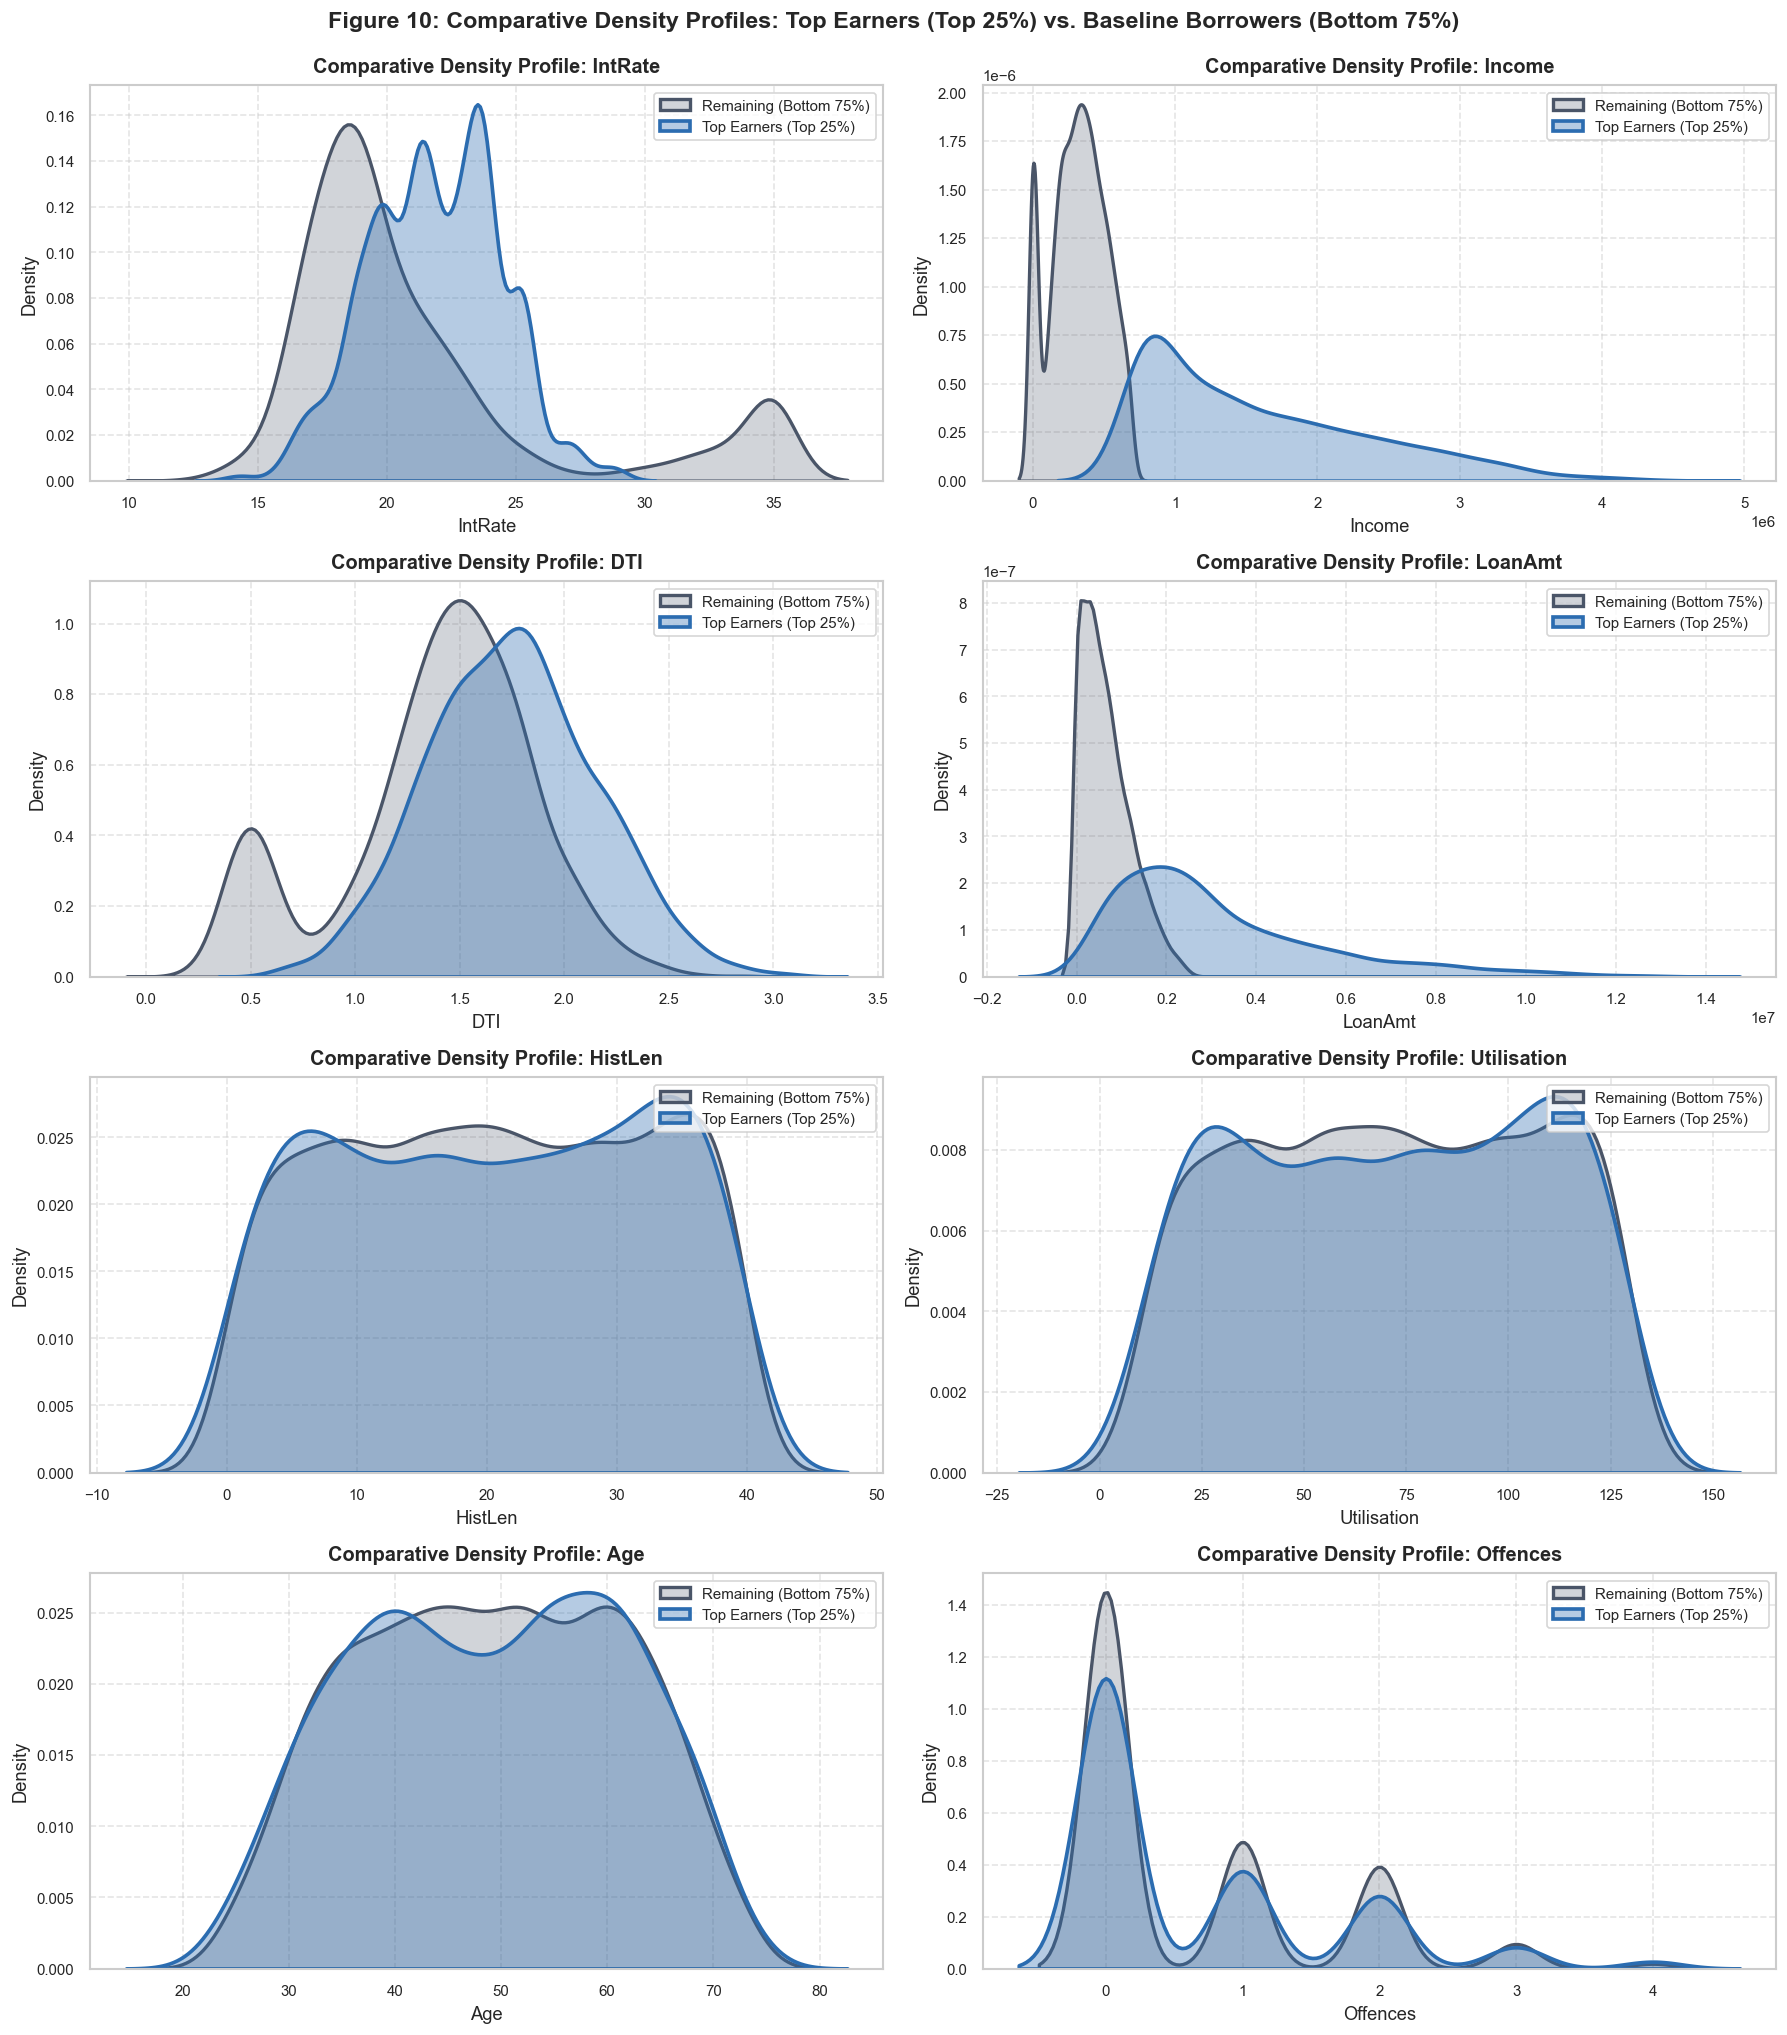

In [17]:
# Figure 10: Comparative Distributional Profiles: Top Earners (Top 25%) vs. Baseline Borrowers (Bottom 75%)
fig, axes = plt.subplots(4, 2, figsize=(15, 17))
axes = axes.flatten()

for idx, col in enumerate(num_vars_analysis):
    ax = axes[idx]
    
    # Overlaid Kernel Density Estimation
    sns.kdeplot(
        data=df_rest, 
        x=col, 
        label='Remaining (Bottom 75%)', 
        color=COLOR_NEUTRAL, 
        fill=True, 
        alpha=0.25, 
        linewidth=2, 
        ax=ax
    )
    sns.kdeplot(
        data=df_top, 
        x=col, 
        label='Top Earners (Top 25%)', 
        color=COLOR_SECONDARY, 
        fill=True, 
        alpha=0.35, 
        linewidth=2.2, 
        ax=ax
    )
    
    ax.set_title(f'Comparative Density Profile: {col}', pad=8)
    ax.set_xlabel(col)
    ax.set_ylabel('Density')
    ax.legend(loc='upper right', frameon=True)

plt.suptitle('Figure 10: Comparative Density Profiles: Top Earners (Top 25%) vs. Baseline Borrowers (Bottom 75%)', y=0.995)
plt.tight_layout()
plt.show()


### 7.4 Comparing the two groups

The overlaid plots in **Figure 10** show that the variables fall into two groups:

- **Variables that differ a lot (size and leverage):**
  - `Income`: No overlap at all, since this is how the groups were split.
  - `LoanAmt`: Clearly separated – top earners' loans are over $\$2.4\text{M}$ higher on average.
  - `DTI`: Clearly shifted to the right – top earners carry more debt relative to income.
  - `IntRate`: A noticeable difference between the groups.
- **Variables that don't change:**
  - `HistLen`, `Utilisation`, `Age` and `Offences`.
  - These four are basically the same for the top 25% and bottom 75% of earners. Having a high income doesn't mean someone manages their credit better or has fewer offences.

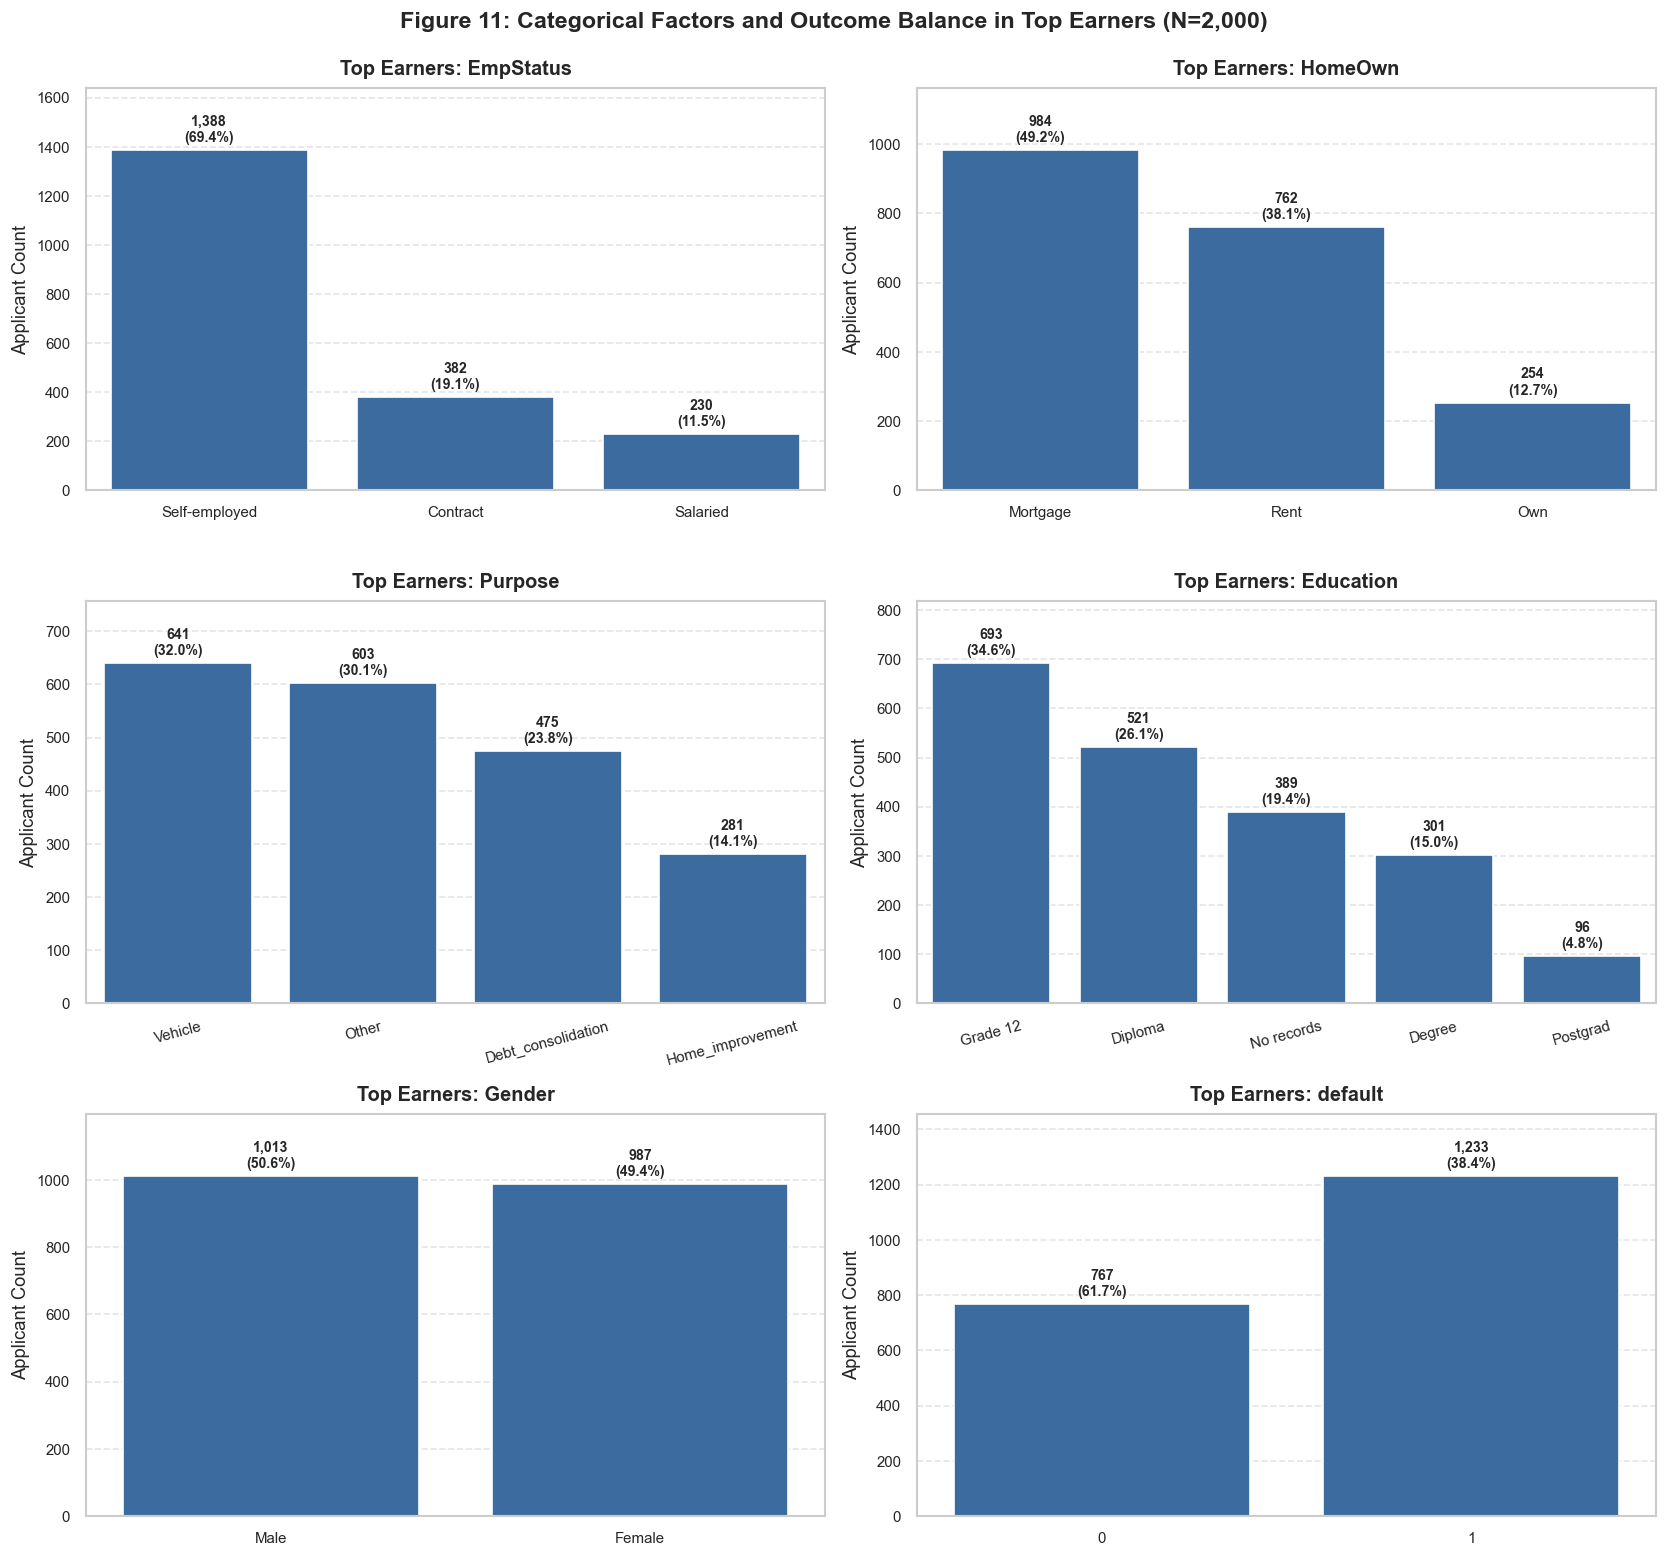

In [19]:
# Figure 11: Categorical Factors and Outcome Variable within Top Earners
cat_vars_analysis = ['EmpStatus', 'HomeOwn', 'Purpose', 'Education', 'Gender', 'default']

fig, axes = plt.subplots(3, 2, figsize=(14, 13))
axes = axes.flatten()

for idx, col in enumerate(cat_vars_analysis):
    ax = axes[idx]
    counts = df_top[col].value_counts()
    percentages = (counts / len(df_top)) * 100
    
    bars = sns.barplot(
        x=counts.index, 
        y=counts.values, 
        color=COLOR_SECONDARY, 
        ax=ax, 
        edgecolor='white'
    )
    
    ax.set_title(f'Top Earners: {col}', pad=8)
    ax.set_ylabel('Applicant Count')
    ax.set_xlabel('')
    
    for p, bar in zip(percentages, bars.patches):
        yval = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2.0, 
            yval + (max(counts.values)*0.015), 
            f'{int(yval):,}\n({p:.1f}%)', 
            ha='center', 
            va='bottom', 
            fontsize=8.5, 
            fontweight='bold'
        )
    ax.set_ylim(0, max(counts.values) * 1.18)
    if len(counts) > 3:
        ax.tick_params(axis='x', rotation=15)

plt.suptitle('Figure 11: Categorical Factors and Outcome Balance in Top Earners (N=2,000)', y=0.995)
plt.tight_layout()
plt.show()


### 7.5 Categorical variables for top earners

**Figure 11** shows what the top earners look like:

1. **Employment status (`EmpStatus`): mostly self-employed**
   - Among top earners, **$69.4\%$ ($1,388$) are Self-employed** and **$19.1\%$ ($382$) are Contract workers**.
   - Only **$11.5\%$ ($230$)** are Salaried, and **$0\%$** are Unemployed.
   - This is the complete opposite of the full dataset, where most borrowers are Salaried ($59.65\%$).
2. **Loan purpose (`Purpose`): fewer vehicle loans**
   - Vehicle loans drop from $42.87\%$ for everyone else to $32.05\%$ for top earners.
   - "Other" goes up from $13.40\%$ to $30.15\%$, and Debt consolidation makes up $23.75\%$.
   - So top earners seem to be borrowing large amounts (mean $\$3.15$M) for general cash flow and business purposes rather than secured vehicle purchases.
3. **Home ownership, education and gender:**
   - Mortgage ($49.2\%$) and Rent ($38.1\%$) are still the most common.
   - Education is very similar to everyone else (Grade 12: $34.7\%$, Diploma: $26.1\%$, Degree: $15.1\%$, Postgrad: $4.8\%$).
   - Gender is still evenly split ($50.65\%$ Male, $49.35\%$ Female).

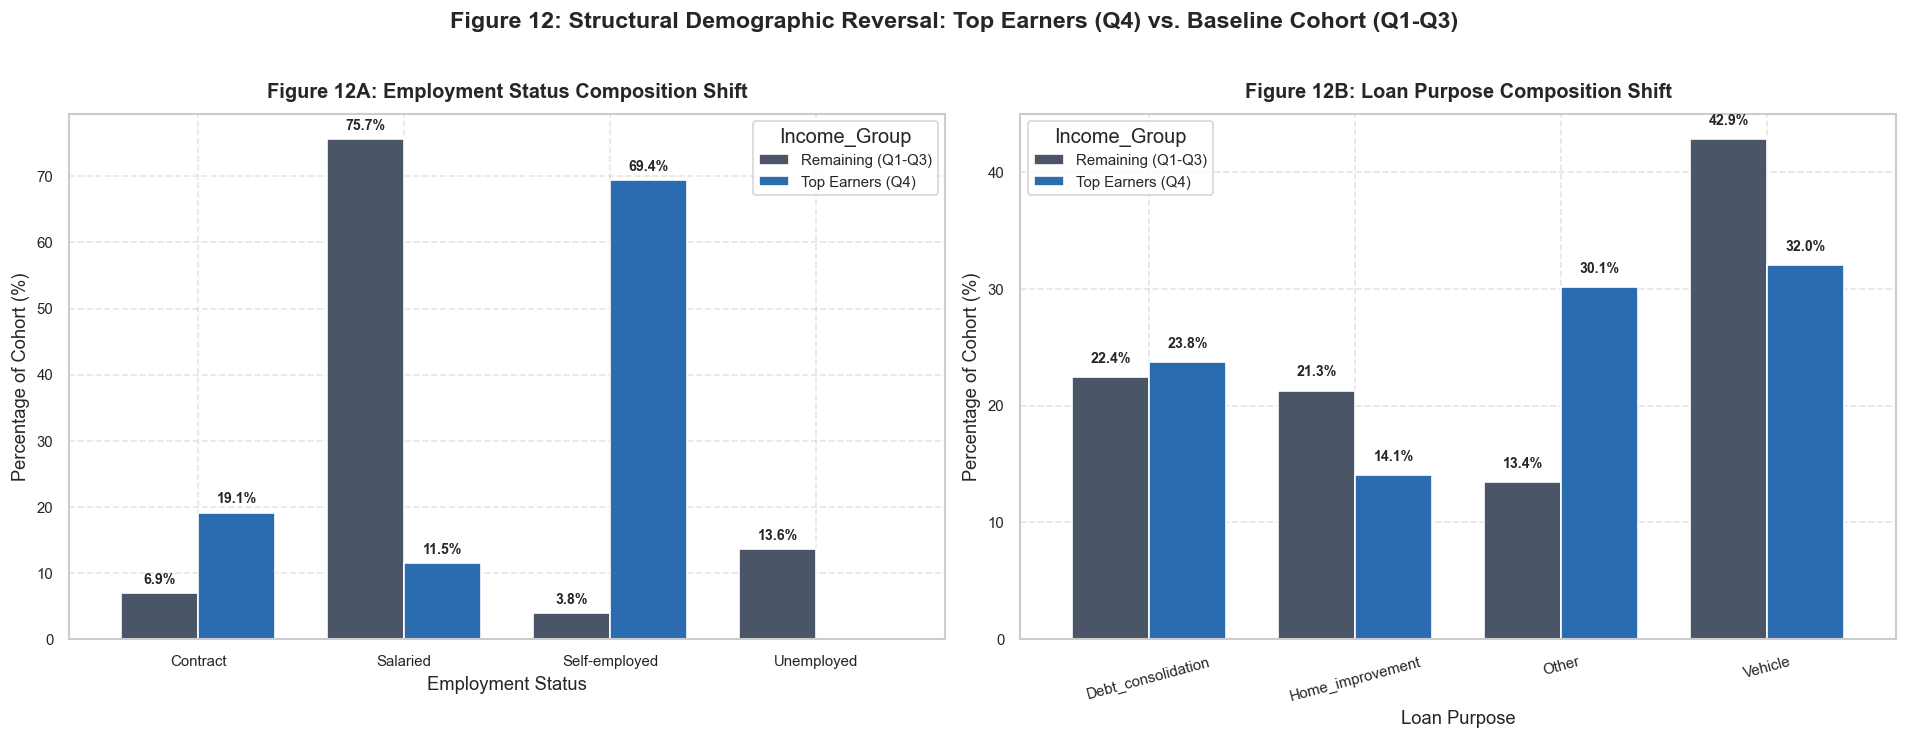

In [20]:
# Figure 12: Structural Shift in Risk Demographics: Top Earners vs. Baseline Cohort
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Employment Status Shift
emp_comp = pd.crosstab(df['EmpStatus'], df['Income_Group'], normalize='columns') * 100
emp_comp[['Remaining (Q1-Q3)', 'Top Earners (Q4)']].plot(
    kind='bar', 
    ax=axes[0], 
    color=[COLOR_NEUTRAL, COLOR_SECONDARY], 
    edgecolor='white', 
    width=0.75
)
axes[0].set_title('Figure 12A: Employment Status Composition Shift', pad=10)
axes[0].set_ylabel('Percentage of Cohort (%)')
axes[0].set_xlabel('Employment Status')
axes[0].tick_params(axis='x', rotation=0)
for p in axes[0].patches:
    if p.get_height() > 0:
        axes[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# Panel B: Purpose Shift
purp_comp = pd.crosstab(df['Purpose'], df['Income_Group'], normalize='columns') * 100
purp_comp[['Remaining (Q1-Q3)', 'Top Earners (Q4)']].plot(
    kind='bar', 
    ax=axes[1], 
    color=[COLOR_NEUTRAL, COLOR_SECONDARY], 
    edgecolor='white', 
    width=0.75
)
axes[1].set_title('Figure 12B: Loan Purpose Composition Shift', pad=10)
axes[1].set_ylabel('Percentage of Cohort (%)')
axes[1].set_xlabel('Loan Purpose')
axes[1].tick_params(axis='x', rotation=15)
for p in axes[1].patches:
    if p.get_height() > 0:
        axes[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.suptitle('Figure 12: Structural Demographic Reversal: Top Earners (Q4) vs. Baseline Cohort (Q1-Q3)', y=1.02)
plt.tight_layout()
plt.show()


### 7.6 Why top earners default more: who they are

**Figure 12** shows the main reason top earners have a higher default rate:

- **Lots of self-employed borrowers:** Self-employed borrowers are only $3.83\%$ of everyone else, but **$69.40\%$ of top earners** (about $18.1\times$ more).
- **Very few salaried borrowers:** Salaried borrowers are $75.70\%$ of everyone else, but only **$11.50\%$ of top earners**.
- As shown in Section 4.5, self-employment comes with a high default rate ($66.96\%$) because business income is less stable, while salaried employment has the lowest default rate ($41.37\%$).
- So the top earner group is made up mostly of the highest-risk employment group in the whole portfolio.

/var/folders/fr/4jzwg0m953bbbwh5bbm8h4700000gn/T/ipykernel_2196/1556727705.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


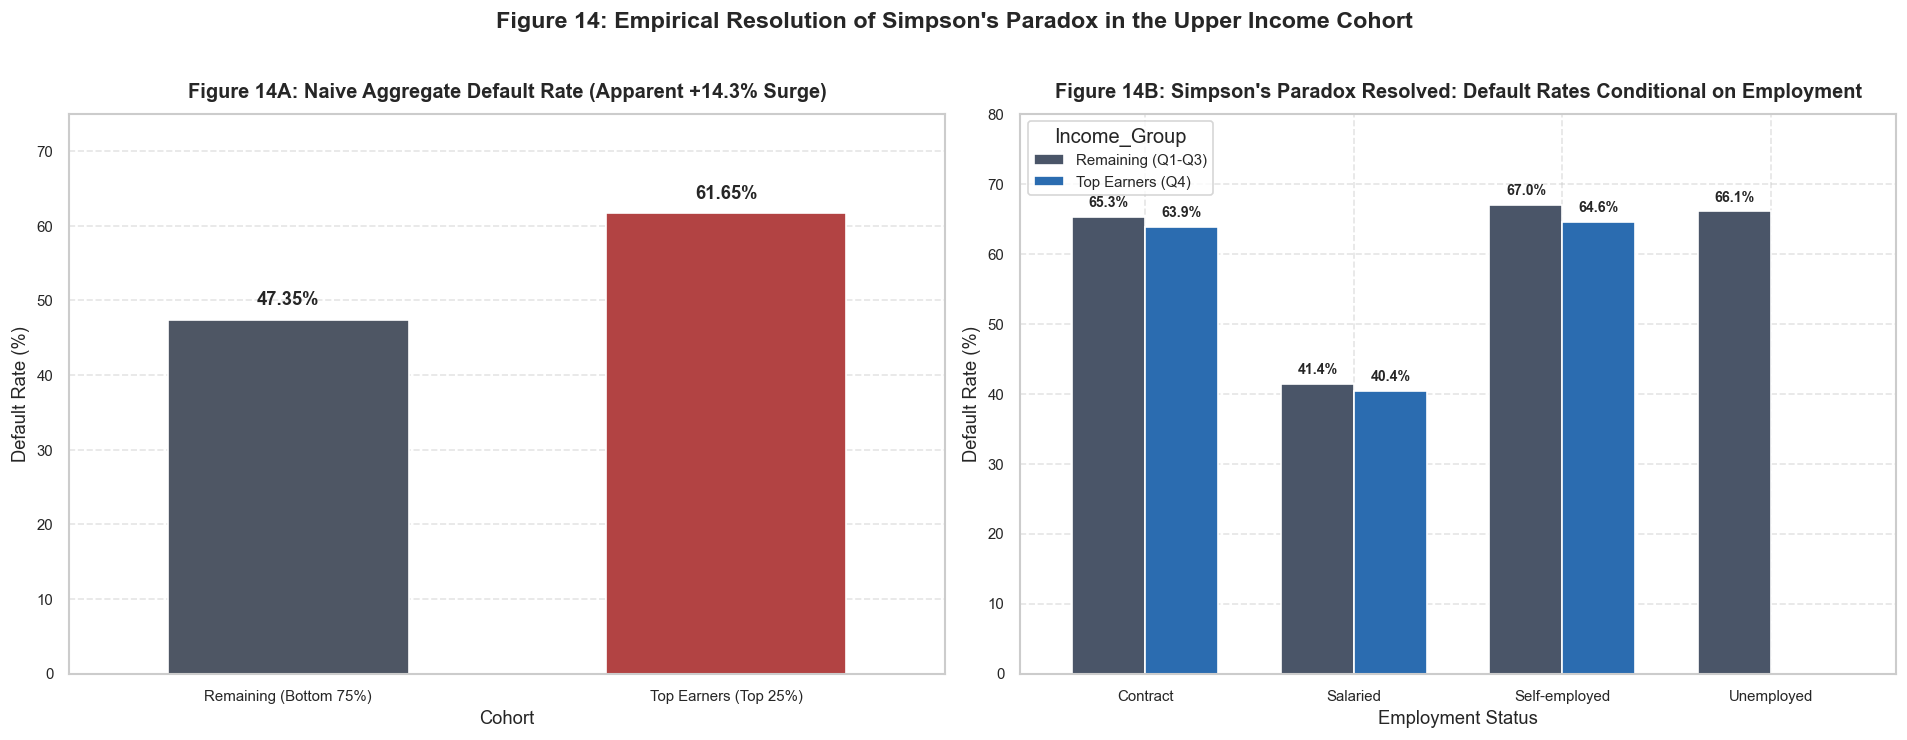

Simpson's Paradox Stratified Cross-Tabulation:


Applicants  Defaults  Default_Rate  Mean_LoanAmt  Mean_DTI  Mean_IntRate
EmpStatus     Income_Group                                                                               
Contract      Remaining (Q1-Q3)         415       271       65.3000      9.45e+05    1.7100       22.7800
              Top Earners (Q4)          382       244       63.8700      2.04e+06    1.7200       22.8400
Salaried      Remaining (Q1-Q3)        4542      1879       41.3700      7.30e+05    1.5000       18.8900
              Top Earners (Q4)          230        93       40.4300      1.65e+06    1.5100       19.0000
Self-employed Remaining (Q1-Q3)         230       154       66.9600      1.23e+06    1.7600       22.0400
              Top Earners (Q4)         1388       896       64.5500      3.70e+06    1.7900       22.0700
Unemployed    Remaining (Q1-Q3)         813       537       66.0500    9,235.5100    0.5000       33.6000

In [21]:
# Figure 13 & 14: Dissecting Risk Drivers and Unraveling Simpson's Paradox
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 14A: Naive Aggregate Default Comparison
agg_comp_df = pd.DataFrame({
    'Cohort': ['Remaining (Bottom 75%)', 'Top Earners (Top 25%)'],
    'Default_Rate': [df_rest['default'].mean()*100, df_top['default'].mean()*100]
})
bars = sns.barplot(
    data=agg_comp_df, 
    x='Cohort', 
    y='Default_Rate', 
    palette=[COLOR_NEUTRAL, COLOR_ACCENT], 
    ax=axes[0], 
    edgecolor='white', 
    width=0.55
)
axes[0].set_title('Figure 14A: Naive Aggregate Default Rate (Apparent +14.3% Surge)', pad=10)
axes[0].set_ylabel('Default Rate (%)')
axes[0].set_ylim(0, 75)
for p in bars.patches:
    axes[0].annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha='center', va='bottom', fontsize=11, fontweight='bold')

# Panel 14B: Simpson's Paradox Resolved: Conditional on Employment Status
emp_simpson = df.groupby(['EmpStatus', 'Income_Group'])['default'].mean().unstack() * 100
emp_simpson[['Remaining (Q1-Q3)', 'Top Earners (Q4)']].plot(
    kind='bar', 
    ax=axes[1], 
    color=[COLOR_NEUTRAL, COLOR_SECONDARY], 
    edgecolor='white', 
    width=0.7
)
axes[1].set_title('Figure 14B: Simpson\'s Paradox Resolved: Default Rates Conditional on Employment', pad=10)
axes[1].set_ylabel('Default Rate (%)')
axes[1].set_xlabel('Employment Status')
axes[1].set_ylim(0, 80)
axes[1].tick_params(axis='x', rotation=0)
for p in axes[1].patches:
    if p.get_height() > 0:
        axes[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.suptitle('Figure 14: Empirical Resolution of Simpson\'s Paradox in the Upper Income Cohort', y=1.02)
plt.tight_layout()
plt.show()

# Cross-Tabulation Proof
simpson_crosstab = df.groupby(['EmpStatus', 'Income_Group']).agg(
    Applicants=('default', 'count'),
    Defaults=('default', 'sum'),
    Default_Rate=('default', lambda x: x.mean() * 100),
    Mean_LoanAmt=('LoanAmt', 'mean'),
    Mean_DTI=('DTI', 'mean'),
    Mean_IntRate=('IntRate', 'mean')
)
print("Simpson's Paradox Stratified Cross-Tabulation:")
display(simpson_crosstab.round(2))


#### 7.8 Explaining the paradox: Simpson's Paradox

The results in **Figure 14** and the cross-tab by employment status show a clear case of Simpson's Paradox:

$$\mathbb{P}(\text{default} \mid \text{Top Earner}) > \mathbb{P}(\text{default} \mid \text{Baseline})$$
$$\text{BUT} \quad \mathbb{P}(\text{default} \mid \text{Top Earner}, \text{EmpStatus} = e) \le \mathbb{P}(\text{default} \mid \text{Baseline}, \text{EmpStatus} = e) \quad \forall e$$

- **Salaried:**
  - Everyone else: $41.37\%$ ($1,879$ / $4,542$)
  - Top earners: **$40.43\%$** ($93$ / $230$)
  - **Top earners default $0.94$ percentage points less.**
- **Self-employed:**
  - Everyone else: $66.96\%$ ($154$ / $230$)
  - Top earners: **$64.55\%$** ($896$ / $1,388$)
  - **Top earners default $2.41$ percentage points less.**
- **Contract:**
  - Everyone else: $65.30\%$ ($271$ / $415$)
  - Top earners: **$63.87\%$** ($244$ / $382$)
  - **Top earners default $1.43$ percentage points less.**
- **Unemployed:**
  - Everyone else: $66.05\%$ ($537$ / $813$). There are no unemployed top earners.

#### So why is the overall default rate higher for top earners?

In the bottom 75%, $75.7\%$ of borrowers are Salaried, which is the low-risk group ($41.4\%$ default). Among top earners, **$88.5\%$ are Self-employed or Contract workers**, which are high-risk groups ($64.6\%$ and $63.9\%$ default).

So the higher default rate for top earners is completely down to **which employment groups they fall into**, not their income. A salaried top earner actually does slightly better than an ordinary salaried borrower – it's just that most people with multimillion-dollar incomes in this data are self-employed and taking out very large loans (mean $\$3.70$M) with less stable income.

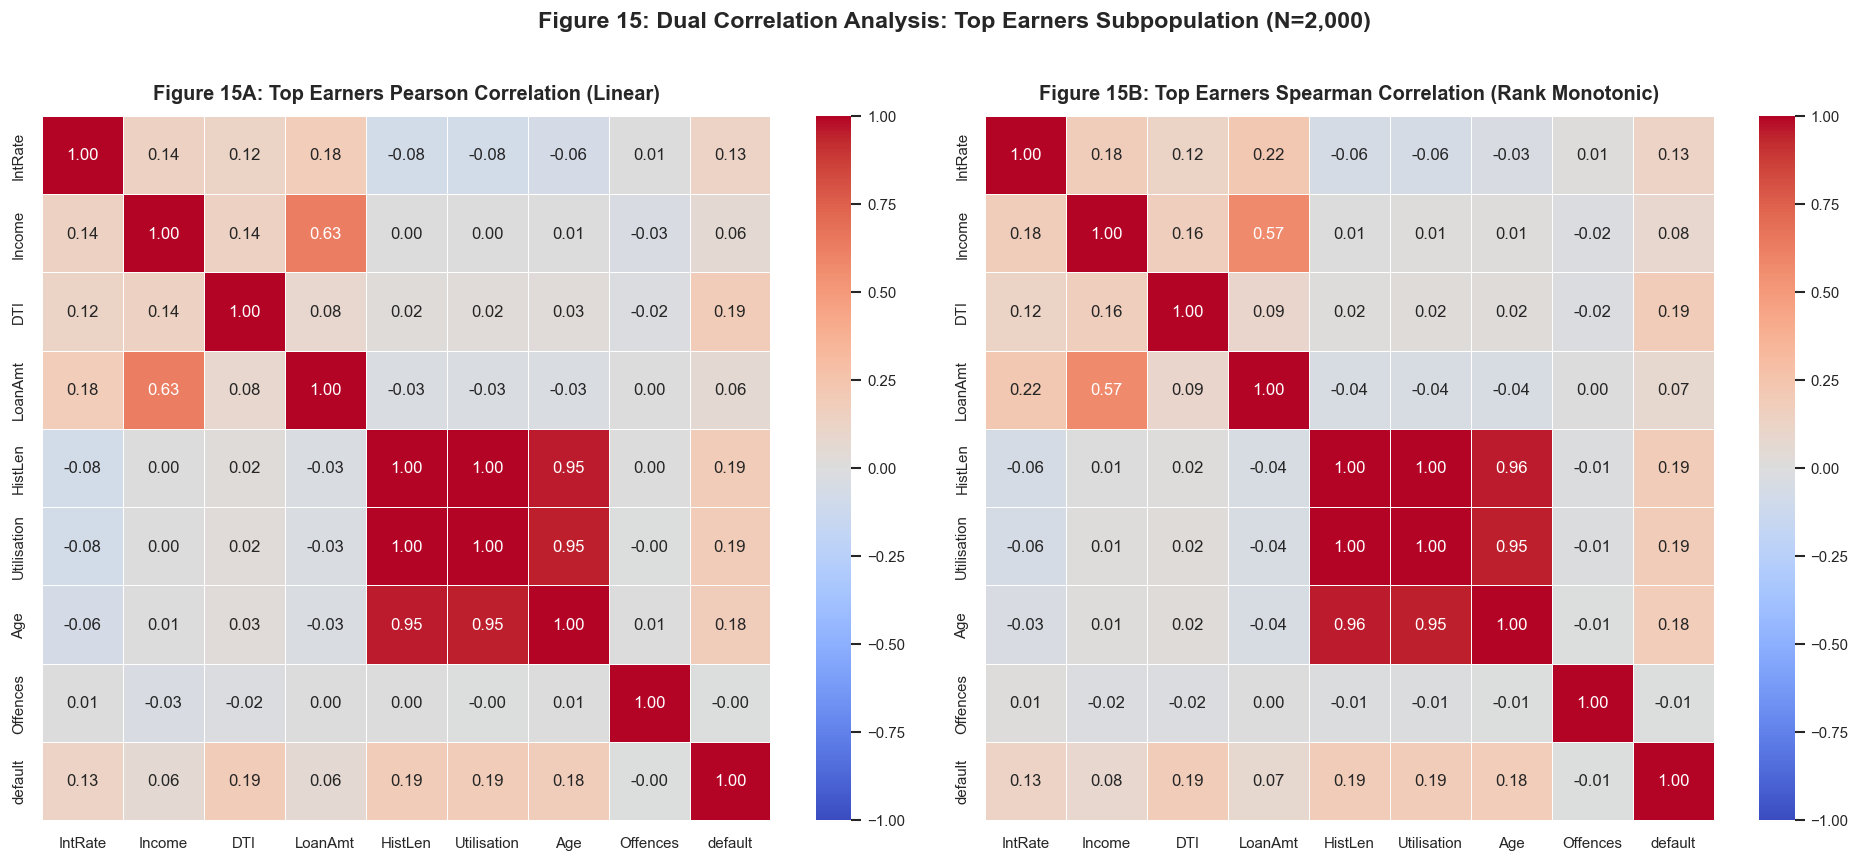

Top Earners Continuous Predictor VIF Values:


,VIF_Top_Earners
Feature,
const,1.0000
Income,1.6900
DTI,1.0200
LoanAmt,1.6600
HistLen,148.5300
Utilisation,136.6400
Age,11.0500
Offences,1.0000


In [22]:
# Figure 15: Dual Correlation Structure and Multicollinearity within Top Earners
top_corr_vars = ['IntRate', 'Income', 'DTI', 'LoanAmt', 'HistLen', 'Utilisation', 'Age', 'Offences', 'default']
top_pearson = df_top[top_corr_vars].corr(method='pearson')
top_spearman = df_top[top_corr_vars].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(
    top_pearson, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    center=0, 
    linewidths=0.5, 
    ax=axes[0]
)
axes[0].set_title('Figure 15A: Top Earners Pearson Correlation (Linear)', pad=10)

sns.heatmap(
    top_spearman, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    center=0, 
    linewidths=0.5, 
    ax=axes[1]
)
axes[1].set_title('Figure 15B: Top Earners Spearman Correlation (Rank Monotonic)', pad=10)

plt.suptitle('Figure 15: Dual Correlation Analysis: Top Earners Subpopulation (N=2,000)', y=1.02)
plt.tight_layout()
plt.show()

# Multicollinearity Check: VIF within Top Earners
X_top_num = sm.add_constant(df_top[['Income', 'DTI', 'LoanAmt', 'HistLen', 'Utilisation', 'Age', 'Offences']])
vif_top = pd.DataFrame({
    'Feature': X_top_num.columns,
    'VIF_Top_Earners': [variance_inflation_factor(X_top_num.values, i) for i in range(X_top_num.shape[1])]
}).set_index('Feature')
print("Top Earners Continuous Predictor VIF Values:")
display(vif_top.round(2))


#### 7.9 Correlations and multicollinearity for top earners

Comparing the top earners' correlation matrix (**Figure 15**) with the full dataset (**Figure 3**) shows two important things:

1. **`HistLen` and `Utilisation` are still almost perfectly correlated ($r = +0.996$):**
   - The correlation is still basically perfect ($r = +0.9963, \rho = +0.9961$), giving extremely high VIFs ($\text{VIF} > 140$).
   - So this collinearity isn't caused by income level – it's built into how the data was generated, across all income groups.
2. **The negative DTI vs. interest rate relationship disappears:**
   - For everyone else (bottom 75%), `DTI` and `IntRate` have a strong negative correlation ($r = -0.645$).
   - For top earners, it **flips to a weak positive correlation ($r = +0.121, \rho = +0.076$)**.
   - *Why:* The negative correlation in the full data comes from unemployed borrowers in the lower income groups, who were charged very high interest rates ($33.6\%$) on small loans and have very low DTIs ($0.50$). Since there are no unemployed top earners, this effect disappears and we get the expected positive relationship between risk and pricing.

---
## Section 8: Final Summary and Recommendations

### Q&A

- **How does splitting the data by income (top 25%, $\ge Q_3$) change the distributions?**
  - Splitting at $Q_3 = \$694,606.25$ shows that top earners are very different from everyone else in loan size (mean $\$3.15$M vs. $\$666$k), leverage (median DTI $1.75$ vs. $1.46$) and employment type ($69.4\%$ Self-employed vs. $3.8\%$). But credit behaviour (utilisation $71.2\%$, history length $20.4$ years) and demographics (age $49$ years, offences $0.68$) stay the same across both groups.
- **Why do top earners default more ($61.65\%$ vs. $47.35\%$)?**
  - This is an example of **Simpson's Paradox**. Most top earners are self-employed ($69.4\%$) or contract workers ($19.1\%$) taking out multimillion-dollar loans for business purposes. Within each employment group, top earners actually default at the same or slightly lower rate than lower earners ($40.4\%$ vs. $41.4\%$ for Salaried, $64.6\%$ vs. $67.0\%$ for Self-employed).
- **Is the multicollinearity problem still there for top earners?**
  - Yes. `HistLen` and `Utilisation` are still almost perfectly correlated ($r = +0.996$) among top earners, so `HistLen` should be dropped from the scorecard no matter the income level.

### Key Findings

- **Income cut-off:** The 75th percentile of income is $\$694,606.25$. Top earners have a mean income of $\$1,580,310$ (median $\$1,363,465$), compared to $\$317,340$ (median $\$322,877$) for everyone else.
- **Much bigger loans:** Top earners have a mean loan of $\$3,149,393$ ($4.73\times$ everyone else) and a median of $\$2,500,454$ ($4.59\times$), with the largest being $\$13,204,499$.
- **Higher leverage:** Top earners have higher DTIs (mean $1.75$ vs. $1.39$), so a higher income doesn't automatically mean less leverage.
- **Different employment mix:** Self-employed borrowers are $69.40\%$ of top earners but only $3.83\%$ of everyone else. Salaried borrowers are only $11.50\%$ of top earners vs. $75.70\%$ of everyone else.
- **Simpson's Paradox:** Within Salaried, top earners default at $40.43\%$ vs. $41.37\%$ for everyone else. Within Self-employed, it's $64.55\%$ vs. $66.96\%$, and within Contract, $63.87\%$ vs. $65.30\%$. So the overall $14.30$ percentage point higher default rate is entirely down to the employment mix.
- **DTI vs. interest rate explained:** The negative correlation between DTI and IntRate in the full data ($r = -0.496$) disappears for top earners ($r = +0.121$), which shows it was driven by unemployed, high-risk borrowers in the lower income groups.

### Next Steps

- **Add interaction terms (`Income` $\times$ `EmpStatus`):** Any logistic regression or scorecard on the full data should include an interaction between income and employment status, so the model doesn't wrongly blame high income for what is really self-employment risk.
- **Drop `HistLen`:** Remove `HistLen` before building the scorecard to fix the extreme collinearity with `Utilisation` ($\text{VIF} > 140$).
- **Set limits for high earners:** Put strict caps on loan size and DTI for self-employed applicants borrowing more than $\$2$M.